# Pérdida esperada (ECL) – Lending Club: modelos de EAD y LGD, ECL y resultado final

Tercero de los tres notebooks del proyecto. `02_modelo_pd.ipynb` deja la **PD** de cada préstamo; aquí se construyen las otras dos piezas del ECL y se calcula el resultado final:

ECL_i = PD_i × LGD_i × EAD_i

- **EAD** (Exposure at Default): cuánto debía el cliente en el momento del impago.
- **LGD** (Loss Given Default): qué parte de esa deuda no se recuperó nunca, entre 0 y 1.

Los dos modelos se entrenan **solo con los préstamos impagados de train** y con **variables de originación**. Las variables de performance (los pagos del préstamo) solo sirven para **construir los targets**, nunca como predictores.

| Notebook | Qué hace |
|---|---|
| **`01_eda.ipynb`** | Carga, EDA, preparación de los datos (transformaciones fijas, split y variables nuevas). Guarda los datos preparados en `data/processed/` |
| **`02_modelo_pd.ipynb`** | Preprocesado, selección de variables y **modelo de PD**. Guarda la PD de validación y test |
| **`03_ead_lgd_ecl.ipynb`** | Targets y modelos de **EAD y LGD**, ECL, margen conservador y resultado final en test |

Los notebooks se ejecutan **en orden**: cada uno lee los ficheros que deja el anterior en `data/processed/`. Python no comparte variables entre notebooks, así que pasar los datos por disco es la forma de encadenarlos.

### El problema de fondo de este notebook

Para entrenar cualquier modelo supervisado hace falta el **valor real** de lo que se quiere predecir. Con la PD era fácil: el dataset trae la columna `y` (impagó sí/no). Pero **no hay ninguna columna** que diga "este préstamo debía X € cuando impagó" ni "de eso se perdió un Y %".

Así que, antes de modelizar nada, hay que **reconstruir la EAD y la LGD reales de cada impagado** a partir de lo que sí hay. Esta primera parte del notebook trata de eso: **fabricar los targets** de los modelos de EAD y LGD y comprobar que están bien construidos.

### Estructura

1. Carga de los datos preparados en `01_eda.ipynb`.
2. Construcción y validación de los targets: EAD, CCF, recobros, LGD y pérdida real.
3. EDA del CCF y la LGD en los impagados de train.
4. Modelo de EAD (target: CCF).
5. Modelo de LGD.
6. ECL en validación y margen conservador.
7. Aplicación a test y resultado final.

In [1]:
# Librerías básicas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import json

pd.set_option("display.max_columns", None)

# Misma paleta que en 01_eda.ipynb: azul = no impago, naranja = impago, gris = referencia
COLOR_NO_IMPAGO, COLOR_IMPAGO = "#2a78d6", "#eb6834"
COLOR_REF = "#52514e"

## 1. Carga de los datos preparados

**Qué hace**: lee train, validación y test tal y como los dejó `01_eda.ipynb` (sección 6), con las transformaciones fijas, el split y las variables nuevas ya aplicados, y las listas de variables de `variables.json`.

Como el split se hizo **una sola vez** en `01_eda.ipynb`, este notebook usa exactamente los mismos préstamos en cada parte que `02_modelo_pd.ipynb`. Es imprescindible: si un préstamo estuviera en train en un notebook y en test en el otro, algún modelo habría visto test.

**Cómo leer la salida**: el tamaño, los impagos y la tasa de impago de cada parte (~13,07% en las tres). El assert comprueba que son las partes del split de `01_eda.ipynb` (5.2).

In [2]:
RUTA_DATOS = "data/processed"
train, val, test = (pd.read_pickle(f"{RUTA_DATOS}/{p}.pkl") for p in ("train", "val", "test"))
with open(f"{RUTA_DATOS}/variables.json", encoding="utf-8") as f:
    variables = json.load(f)
assert (len(train), len(val), len(test)) == (1_369_371, 342_343, 427_929), "No son las partes de 01_eda.ipynb"

pd.DataFrame({
    "n_prestamos": [len(p) for p in (train, val, test)],
    "n_impagos": [int(p["impago"].sum()) for p in (train, val, test)],
    "tasa_impago_pct": [p["impago"].mean() * 100 for p in (train, val, test)],
}, index=["train", "validación", "test"]).round(2)

,n_prestamos,n_impagos,tasa_impago_pct
train,1369371,179018,13.07
validación,342343,44755,13.07
test,427929,55943,13.07


## 2. Construcción de los targets de EAD y LGD

### 2.1 Con qué variables contamos y por qué no basta con leerlas

Solo tenemos el **importe financiado** y las **variables de performance**, que son un resumen de los pagos del préstamo:

| Columna | Qué es |
|---|---|
| `funded_amnt` | Importe financiado: lo que se prestó |
| `princ_rec` | Principal recibido: cuánto capital ha devuelto el cliente |
| `interest_rec` | Intereses recibidos |
| `late_fees_rec` | Comisiones por mora recibidas |
| `paym_rec_for_tot_amnt_fund` | Total de pagos recibidos: todo el dinero que ha entrado de ese préstamo |
| `remaining_princ_for_tot_amnt_fund` | Principal pendiente: lo que queda por devolver |

Con esto hay que deducir dos cosas: la **EAD** (cuánto se debía al impagar) y la **LGD** (qué parte de eso no se recuperó).

**Por qué la EAD no es el principal pendiente.** Lo intuitivo sería decir que la EAD es `remaining_princ_for_tot_amnt_fund`. Pero cuando un préstamo se da por perdido, Lending Club lo **da de baja** (*write-off* o *charge-off*): borra el saldo pendiente de sus libros porque lo reconoce como pérdida. La columna refleja **cómo quedó la contabilidad, no cuánto se debía**. Si la usáramos tal cual, la mayoría de los impagos tendría exposición 0 y "no habríamos perdido nada", lo cual es absurdo.

**Por qué la LGD no se puede leer.** LGD = pérdida / EAD, y pérdida = EAD − lo recuperado **después del impago**. Pero no hay columna de recobros: solo el total de pagos recibidos, que mezcla todo lo que ha entrado a lo largo de la vida del préstamo (cuotas normales de principal e intereses, comisiones y, si las hubo, recuperaciones posteriores al impago).

**Qué hace la celda**: compara, en **train**, el porcentaje de préstamos con principal pendiente igual a 0 entre impagados y no impagados, y la media de lo que "falta" en cada grupo: lo prestado menos lo devuelto menos lo pendiente.

**Cómo leerlo**: en los no impagados, un pendiente de 0 significa que ya han terminado de pagar (préstamos vencidos), y lo que falta es 0: la contabilidad cuadra. En los impagados, un pendiente de 0 en casi todos los casos significa **baja contable**, y lo que falta es el importe dado por perdido. Es la prueba de que `remaining_princ_for_tot_amnt_fund` no sirve como EAD.

In [3]:
PERFORMANCE = ["princ_rec", "interest_rec", "late_fees_rec",
               "paym_rec_for_tot_amnt_fund", "remaining_princ_for_tot_amnt_fund"]
assert train[["funded_amnt"] + PERFORMANCE].notna().all().all(), "Hay nulos en las columnas de los targets"

falta = train["funded_amnt"] - train["princ_rec"] - train["remaining_princ_for_tot_amnt_fund"]
pd.DataFrame({
    "n": train.groupby("impago").size(),
    "% con pendiente = 0": (train["remaining_princ_for_tot_amnt_fund"] <= 0.01).groupby(train["impago"]).mean() * 100,
    "media prestado − devuelto − pendiente (€)": falta.groupby(train["impago"]).mean(),
}).rename(index={0: "no impago", 1: "impago"}).round(2)

,n,% con pendiente = 0,media prestado − devuelto − pendiente (€)
impago,,,
no impago,1190353,55.49,0.00
impago,179018,91.79,10134.56


### 2.2 Definiciones de EAD, recobros, LGD y pérdida real

**EAD: se reconstruye.** EAD = lo prestado − el principal que ya había devuelto:

EAD = funded_amnt − princ_rec

Mide lo que quedaba pendiente **justo antes de la baja contable**. Como target del modelo de EAD usaremos la proporción sobre el importe prestado, el **CCF** (*credit conversion factor*):

CCF = EAD / funded_amnt, entre 0 y 1

El CCF es mejor target que la EAD en euros porque quita el efecto escala: un préstamo de 30.000 € y otro de 3.000 € que impagan en el mismo momento de su vida tienen el mismo CCF. Al aplicar el modelo, EAD_i = CCF_i × funded_amnt_i.

**Recobros: lo que sobra de los pagos normales.** Si todo lo cobrado se reparte en principal, intereses, comisiones y recobros posteriores al impago, entonces:

recobros = paym_rec_for_tot_amnt_fund − princ_rec − interest_rec − late_fees_rec

Es decir, el dinero que **no se explica con los pagos normales** del préstamo. Solo cuenta como recuperación lo cobrado **después del impago**:
- los intereses pagados antes del impago no recuperan la deuda: son lo que el banco cobra por prestar, su ingreso normal;
- el principal pagado antes del impago ya está descontado en la EAD.

Es la definición correcta de LGD (mide qué pasa con la deuda a partir del impago) y además es la **conservadora**: contar los intereses como recobros rebajaría artificialmente la pérdida, justo lo que penalizaría un regulador.

**LGD y pérdida real:**
- recobros recortados a [0, EAD]: no se puede recuperar menos de 0 ni más de lo que se debe;
- LGD = 1 − recobros / EAD;
- pérdida real = EAD × LGD = EAD − recobros si el préstamo impagó, y **0 si no impagó**.

**Qué hace la celda**: define `crear_targets(data)`, que añade estas columnas fila a fila, y la aplica a train, validación y test.
- Es una **regla fija**: no aprende nada de los datos (no hay medias ni cuantiles), así que aplicarla a validación y test **no es fuga de información**. Igual que el target `impago`, estas columnas son la "verdad" contra la que se evalúa.
- La pérdida real de validación servirá para calibrar el margen conservador; la de test, para la evaluación final.
- `ead`, `ccf`, `recobros` y `lgd` solo tienen sentido en los impagados; en los no impagados quedan a NaN. La pérdida real sí está en todos: vale 0 si no impaga.
- **EAD ≈ 0**: si el cliente había devuelto casi todo antes de impagar (EAD < 1 €), la LGD sería dividir entre casi 0. Su LGD se deja a NaN y la columna `apto_lgd` vale False: **se excluyen solo del entrenamiento del modelo de LGD**. Siguen en la cartera con su pérdida real ≈ 0, así que no se excluye ninguna fila del análisis.

**Cómo leer la salida**: estadísticos de las columnas nuevas en los impagados de train. El CCF debe estar entre 0 y 1 y la LGD también.

In [4]:
EAD_MINIMA = 1.0   # € : por debajo, la LGD (recobros / EAD) no está bien definida


def crear_targets(data):
    """Targets observados de EAD y LGD (regla fija, fila a fila: no aprende nada de los datos)."""
    data = data.copy()
    impago = data["impago"] == 1
    ead = data["funded_amnt"] - data["princ_rec"]
    recobros_brutos = (data["paym_rec_for_tot_amnt_fund"] - data["princ_rec"]
                       - data["interest_rec"] - data["late_fees_rec"])
    recobros = recobros_brutos.clip(lower=0).clip(upper=ead.clip(lower=0))

    data["ead"] = ead.where(impago)
    data["ccf"] = (ead / data["funded_amnt"]).where(impago)
    data["recobros_brutos"] = recobros_brutos.where(impago)        # sin recortar, para las validaciones
    data["recobros"] = recobros.where(impago)
    data["apto_lgd"] = impago & (ead >= EAD_MINIMA)
    data["lgd"] = (1 - recobros / ead).where(data["apto_lgd"])
    data["perdida_real"] = (ead.clip(lower=0) - recobros).where(impago, 0.0)
    return data


cols_target = ["ead", "ccf", "recobros_brutos", "recobros", "lgd", "perdida_real"]
n_filas = [len(p) for p in (train, val, test)]
train, val, test = (crear_targets(p) for p in (train, val, test))
assert [len(p) for p in (train, val, test)] == n_filas, "Cambian las filas"

imp_train = train[train["impago"] == 1]
imp_train[cols_target].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
ead,179018.0,11013.862,7716.319,0.00,4885.140,9358.520,15379.222,40000.00
ccf,179018.0,0.690,0.222,0.00,0.555,0.740,0.868,1.00
recobros_brutos,179018.0,1076.970,1774.185,-0.01,0.000,404.337,1545.408,39859.55
recobros,179018.0,1075.330,1759.888,0.00,0.000,404.325,1545.113,37309.92
lgd,178958.0,0.902,0.130,0.00,0.859,0.903,1.000,1.00
perdida_real,179018.0,9938.532,7156.334,0.00,4301.732,8397.215,13929.632,40000.00


### 2.3 Validación de las fórmulas

Las definiciones de 2.2 son **hipótesis sobre cómo se construyen las columnas** de Lending Club: no se pueden leer, así que hay que comprobarlas con los propios datos. Si son correctas, se tienen que cumplir unas identidades contables. Todas se comprueban **en train** y la tabla muestra el error máximo en euros (céntimos = redondeo).

1. **EAD en los impagados con saldo vivo.** Hay impagados a los que todavía **no se les ha borrado el saldo** (`remaining_princ_for_tot_amnt_fund` > 0). En ellos el principal pendiente es la EAD real, así que se puede comparar con la fórmula funded − princ_rec. **Si coinciden donde se puede verificar, nos fiamos de la fórmula en el resto**, donde la baja contable ha borrado el dato.
2. **Contabilidad en los no impagados.** Sin baja contable debe cumplirse funded = princ_rec + pendiente. Es la misma identidad que la del punto 1, comprobada en 1,2 millones de préstamos.
3. **Recobros nunca negativos.** Si los recobros son "lo que sobra" de los pagos normales, ese sobrante **no puede ser negativo** (no se recupera menos de 0). Si hubiera negativos relevantes, el total de pagos no se repartiría como suponemos y la fórmula estaría mal.
4. **Sin recobros en los no impagados.** Si un préstamo no ha impagado no puede haber recobros, así que el sobrante debe ser 0 exacto: el total de pagos es exactamente principal + intereses + comisiones.

**Cómo leer la tabla**:
- `n`: número de préstamos donde se comprueba la identidad.
- `error máximo (€)`: la mayor diferencia entre los dos lados; en el punto 3, cuánto baja el recobro más negativo de 0.
- `n con error > 1 €`: cuántos préstamos fallan por más de 1 €.

Diferencias de céntimos son redondeo. Unos pocos casos de 1–2 € en millones de préstamos son el ajuste de la última cuota (préstamos ya pagados en los que el principal devuelto se queda un par de euros por debajo de lo prestado), no un fallo de la fórmula. El assert detiene el notebook si algún error supera los 5 € o si hay más de 10 casos por encima de 1 €: eso sí indicaría que la identidad no se cumple.

In [5]:
no_imp_train = train[train["impago"] == 0]
con_saldo = imp_train[imp_train["remaining_princ_for_tot_amnt_fund"] > 0.01]
sobrante_no_imp = (no_imp_train["paym_rec_for_tot_amnt_fund"] - no_imp_train["princ_rec"]
                   - no_imp_train["interest_rec"] - no_imp_train["late_fees_rec"])

errores = [   # diferencia entre los dos lados de cada identidad (en la 3, solo cuenta la parte negativa)
    (con_saldo["ead"] - con_saldo["remaining_princ_for_tot_amnt_fund"]).abs(),
    (no_imp_train["funded_amnt"] - no_imp_train["princ_rec"] - no_imp_train["remaining_princ_for_tot_amnt_fund"]).abs(),
    (-imp_train["recobros_brutos"]).clip(lower=0),
    sobrante_no_imp.abs(),
]
validaciones = pd.DataFrame({
    "n": [len(e) for e in errores],
    "error máximo (€)": [e.max() for e in errores],
    "n con error > 1 €": [int((e > 1).sum()) for e in errores],
}, index=["1. EAD = pendiente (impagados con saldo vivo)",
          "2. funded = principal devuelto + pendiente (no impagados)",
          "3. recobros ≥ 0 (impagados, valor mínimo)",
          "4. recobros = 0 (no impagados)"])

assert (validaciones["error máximo (€)"] < 5).all() and (validaciones["n con error > 1 €"] <= 10).all(), \
    "Alguna identidad no se cumple"
print(f"Impagados de train: {len(imp_train):,}; con saldo vivo: {len(con_saldo):,} "
      f"({len(con_saldo) / len(imp_train):.1%}); dados de baja: {1 - len(con_saldo) / len(imp_train):.1%}")
validaciones.round(2)

Impagados de train: 179,018; con saldo vivo: 14,699 (8.2%); dados de baja: 91.8%


,n,error máximo (€),n con error > 1 €
1. EAD = pendiente (impagados con saldo vivo),14699,0.31,0
2. funded = principal devuelto + pendiente (no impagados),1190353,2.00,2
"3. recobros ≥ 0 (impagados, valor mínimo)",179018,0.01,0
4. recobros = 0 (no impagados),1190353,0.01,0


### 2.4 Casos raros y realismo de los targets

Con las fórmulas validadas, quedan dos casos raros que la función de 2.2 ya trata, y que aquí contamos para saber cuánto pesan:

- **EAD ≈ 0** (EAD < 1 €): el cliente había devuelto casi todo antes de impagar. Su LGD no está definida; se excluyen **solo** del entrenamiento del modelo de LGD (`apto_lgd = False`). Su pérdida real es ≈ 0.
- **Recobros mayores que la EAD**: se ha recuperado más de lo que se debía (por ejemplo, intereses de demora cobrados en el recobro). Se limitan a la EAD, así que LGD = 0: no se puede perder menos que nada.

Y una comprobación de **realismo** de los targets resultantes:
- **% de impagados sin ningún recobro**: en préstamos personales sin garantía es habitual que una parte grande no recupere nada.
- **LGD media**, simple y ponderada por EAD. La ponderada es la que importa para el ECL en euros, porque los préstamos grandes pesan más en la pérdida. En crédito al consumo sin garantía se esperan LGD altas, del 70–90%.
- **CCF medio**: qué proporción del préstamo se debía de media al impagar.

**Cómo leer la salida**: los casos raros deben ser una fracción mínima de los impagados (si fueran muchos, las fórmulas estarían fallando en algún tipo de préstamo). Las cifras de realismo deben estar en los rangos citados.

In [6]:
apto = imp_train[imp_train["apto_lgd"]]
resumen_targets = pd.Series({
    "impagados en train": len(imp_train),
    "EAD < 1 € (fuera del entrenamiento de LGD)": (~imp_train["apto_lgd"]).sum(),
    "recobros > EAD (recortados, LGD = 0)": (imp_train["recobros_brutos"] > imp_train["ead"]).sum(),
    "% sin ningún recobro": (imp_train["recobros"] <= 0.01).mean() * 100,
    "CCF medio": imp_train["ccf"].mean(),
    "LGD media": apto["lgd"].mean(),
    "LGD ponderada por EAD": (apto["ead"] * apto["lgd"]).sum() / apto["ead"].sum(),
    "pérdida real total en train (M€)": train["perdida_real"].sum() / 1e6,
}, name="valor")
resumen_targets.round(3).to_frame()

,valor
impagados en train,179018.000
EAD < 1 € (fuera del entrenamiento de LGD),60.000
"recobros > EAD (recortados, LGD = 0)",618.000
% sin ningún recobro,37.444
CCF medio,0.690
LGD media,0.902
LGD ponderada por EAD,0.902
pérdida real total en train (M€),1779.176


### 2.5 Distribución de los targets en los impagados de train

**Qué se muestra**: el histograma del **CCF** y el de la **LGD** en los impagados de train (para la LGD, los aptos), como porcentaje de préstamos. Debajo, una tabla por **año de concesión** con la LGD media y el % de impagados con saldo vivo (no dados de baja todavía).

**Por qué importa la forma de la distribución**: decide qué modelo tiene sentido.
- Si el CCF tiene una forma suave, una regresión acotada a [0, 1] lo modelizará bien.
- La LGD de los préstamos sin garantía suele estar **muy concentrada en 1** (los que no recuperan nada) con una cola hacia valores bajos. Una distribución así se predice mal con un solo número, y es habitual modelizarla por segmentos.

**Por qué por año de concesión**: los impagados que aún tienen saldo vivo **no han terminado el proceso de recobro**. Hasta ahora no han recuperado nada, así que su LGD observada es 1, aunque en el futuro quizá recuperen algo. Esto se concentra en las **añadas recientes**. Es un sesgo conservador (sobreestima la pérdida), pero hay que tenerlo presente en el modelo de LGD: es el equivalente, para la LGD, de la inmadurez que vimos en la PD.

**Cómo leerlo**: en la tabla, si la LGD media sube en los últimos años a la vez que el % con saldo vivo, ese aumento es en parte proceso de recobro sin terminar, no clientes peores.

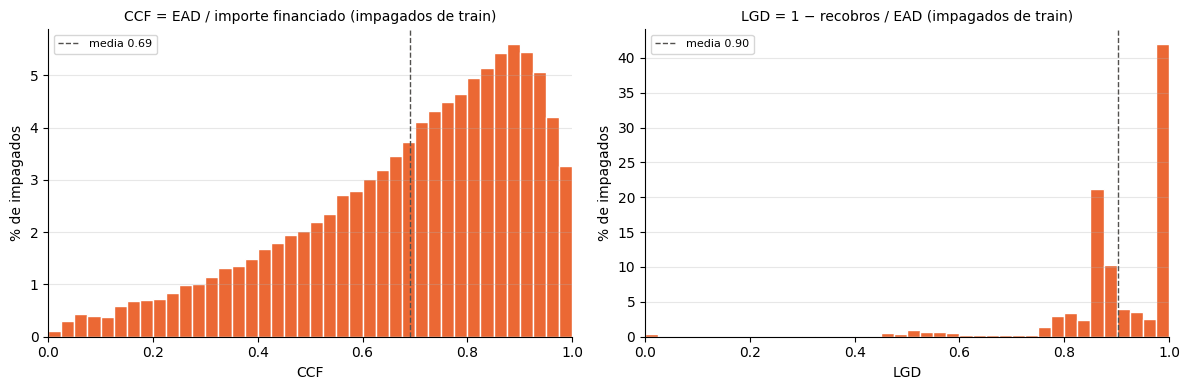

,n impagados,LGD media,% con saldo vivo,LGD media (dados de baja)
año de concesión,,,,
2007,88,0.918,0.000,0.918
2008,320,0.903,0.000,0.903
2009,489,0.906,0.000,0.906
2010,1103,0.911,0.000,0.911
2011,2056,0.905,0.000,0.905
2012,5598,0.887,0.000,0.887
2013,13455,0.870,0.037,0.870
2014,26616,0.872,1.063,0.871
2015,49316,0.884,2.356,0.881


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (col, datos, titulo) in zip(axes, [("ccf", imp_train, "CCF = EAD / importe financiado"),
                                           ("lgd", apto, "LGD = 1 − recobros / EAD")]):
    pesos = np.full(len(datos), 100 / len(datos))
    ax.hist(datos[col], bins=np.linspace(0, 1, 41), weights=pesos, color=COLOR_IMPAGO, edgecolor="white")
    ax.axvline(datos[col].mean(), color=COLOR_REF, ls="--", lw=1, label=f"media {datos[col].mean():.2f}")
    ax.set_xlim(0, 1)
    ax.set_xlabel(col.upper())
    ax.set_ylabel("% de impagados")
    ax.set_title(f"{titulo} (impagados de train)", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

saldo_vivo = apto["remaining_princ_for_tot_amnt_fund"] > 0.01
pd.DataFrame({
    "n impagados": apto.groupby("issue_date_year").size(),
    "LGD media": apto.groupby("issue_date_year")["lgd"].mean(),
    "% con saldo vivo": saldo_vivo.groupby(apto["issue_date_year"]).mean() * 100,
    "LGD media (dados de baja)": apto[~saldo_vivo].groupby("issue_date_year")["lgd"].mean(),
}).rename_axis("año de concesión").round(3)

### 2.6 Conclusiones de la construcción de los targets

**Las fórmulas están validadas con los propios datos (2.3):**
- **EAD = funded − princ_rec** coincide con el principal pendiente real en los 14.699 impagados de train que aún tienen saldo vivo (8,2%). El error máximo es de 0,31 €. En el 91,8% restante, la baja contable ha borrado el saldo, y por eso hace falta la fórmula.
- **Recobros = total cobrado − principal − intereses − comisiones** nunca es negativo (como mucho −0,01 €) y vale 0 exacto en todos los no impagados. El reparto de los pagos que suponemos es el correcto.
- La identidad contable de los no impagados solo falla en 2 préstamos, por 2 € como máximo: ajuste de la última cuota.

**Los targets son realistas (2.4 y 2.5):**
- **CCF medio 0,69**: al impagar se debía de media el 69% de lo prestado. La distribución es suave, con la mayor parte entre 0,6 y 1, porque se impaga sobre todo al principio de la vida del préstamo. Una regresión acotada a [0, 1] encaja bien.
- **LGD media 0,90**, igual simple que ponderada por EAD. El 37% de los impagados no recupera nada.
- Casos raros mínimos: **60** impagados con EAD < 1 € (fuera solo del entrenamiento de LGD) y **618** con recobros > EAD (recortados a LGD = 0).
- Pérdida real total en train: **1.779 M€**.

**La LGD no tiene una distribución "normal":** el 37% está exactamente en 1 (sin ningún recobro), otro 5% entre 0,975 y 1, y hay un pico muy marcado alrededor de **0,86**. Casi no hay préstamos por debajo de 0,75. Un recobro de ~14% repetido en muchos préstamos sugiere un mecanismo fijo, como la venta de la deuda impagada a una agencia de recobro por un porcentaje del saldo. Para el modelo de LGD tiene dos consecuencias:
- hay **poca variabilidad que explicar** (desviación típica 0,13): un modelo complejo ganará poco frente a medias por segmento;
- más que predecir "cuánto se recobra", el modelo tiene que distinguir **si hay recobro o no**.

**Recobro sin terminar en las añadas recientes:** la LGD media sube de ~0,87–0,88 (2013–2015) a 0,94 en 2017 y 0,99 en 2018, a la vez que crece el % de impagados con saldo vivo (20% y 53%). Incluso los ya dados de baja en 2018 tienen LGD 0,98: no ha dado tiempo a recobrar. Es la **inmadurez de la LGD**:
- sobreestima la pérdida, así que es conservadora;
- igual que en la PD, el modelo de LGD tendrá que tener en cuenta la madurez (año o `meses_en_cartera`). Si no, mezclará préstamos con el recobro terminado y sin terminar.

**Siguiente paso:** EDA de CCF y LGD frente a las variables de originación en los impagados de train (plazo, madurez, tipo de interés, finalidad, ingresos...). Servirá para decidir los modelos de EAD y LGD.

## 3. EDA del CCF y la LGD en los impagados de train

Ya tenemos los targets. Antes de modelizar, miramos **qué variables de originación se relacionan con el CCF y con la LGD**. Es el equivalente, para EAD y LGD, a la sección 4 de `01_eda.ipynb` (EDA frente al impago). Servirá para decidir:
- si merece la pena un modelo (LightGBM) o bastan unas **medias por segmento**;
- qué segmentos usar como **referencia** en los modelos de las secciones 4 y 5.

**Todo se hace con los impagados de train**: es la población con la que se entrenarán los modelos de EAD y LGD. Validación y test no se miran.

### 3.1 Variables candidatas

**Qué hace**: monta la lista de candidatas con las listas de `variables.json`. Son las **40 del conjunto C** con el que se entrenó la PD final (`02_modelo_pd.ipynb`, 7.1):
- 16 continuas;
- 11 conteos;
- las 4 variables nuevas;
- 9 categóricas.

El año y el mes de concesión no entran como predictores: los sustituye la madurez, como en la PD. Todas las variables ya vienen preparadas de `01_eda.ipynb` (fechas, `emp_length_num`, `emp_title_clean`, DTI corregido y variables nuevas).

**Cómo leer la salida**: los asserts garantizan que las 40 candidatas existen y que ninguna es de performance, ni `grade`, ni uno de los targets recién construidos. Se imprime el número de impagados con el que se hace el EDA.

In [8]:
continuas, conteos, categoricas = variables["continuas"], variables["conteos"], variables["categoricas"]
vars_nuevas = variables["vars_nuevas"]
cats_cand = [c for c in categoricas if c not in ("issue_date_year", "issue_date_month")]
candidatas = continuas + list(conteos) + vars_nuevas + cats_cand

# Comprobaciones
assert len(candidatas) == 40 and set(candidatas) <= set(train.columns)
prohibidas = set(PERFORMANCE) | set(variables["forbidden"]) | {"impago", "apto_lgd"} | set(cols_target)
assert not set(candidatas) & prohibidas, "Hay variables no permitidas entre las candidatas"

# Impagados de train (y aptos para LGD)
imp_train = train[train["impago"] == 1].copy()
imp_train["sin_recobro"] = imp_train["recobros"] <= 0.01
apto = imp_train[imp_train["apto_lgd"]]
print(f"{len(candidatas)} candidatas | impagados de train: {len(imp_train):,} | aptos para LGD: {len(apto):,}")

40 candidatas | impagados de train: 179,018 | aptos para LGD: 178,958


### 3.2 Ranking de relevancia de las variables para el CCF y para la LGD

En la PD, el ranking se hizo con el **Information Value**, pero el IV solo sirve para targets binarios. El CCF y la LGD son **continuos** (entre 0 y 1), así que usamos el equivalente:

**% de varianza explicada por los grupos (eta², o razón de correlación).**
- Cada variable se parte en grupos igual que para el IV: **deciles** las continuas, **valores** con la cola agrupada en "k+" los conteos, **categorías** tal cual las categóricas, y los nulos en un grupo "missing".
- eta² = 1 − (varianza del target dentro de los grupos) / (varianza total del target).
- Es la proporción de la variabilidad del CCF (o de la LGD) que se explicaría solo con la media de cada grupo. 0% = la variable no dice nada; 100% = la explica por completo.
- Igual que el IV, **sirve para numéricas y categóricas a la vez** y **capta relaciones no monótonas**.
- Un detalle: con muchas categorías sube un poco solo por azar. Con 179.000 impagados es despreciable, ~0,1 puntos para las 207 profesiones.

**Spearman** (solo para las variables ordenables): añade el **signo**. Positivo = a más valor de la variable, más CCF (o más LGD).

**Qué hace la celda**: calcula las dos medidas para las 40 candidatas, con el CCF en todos los impagados y con la LGD en los aptos.

**Cómo leer la tabla**: ordenada por eta² del CCF.
- Para tener una referencia: en un target tan ruidoso como la LGD, un eta² del 1% ya es una señal apreciable. Del 5% en adelante, la variable es importante.
- Si todas las variables tienen eta² muy bajo para la LGD, un modelo complejo ganará poco frente a medias por segmento.
- **Es solo una guía, no se quita ninguna variable**: como en la PD, se le da todo al modelo y el árbol decide.

In [9]:
def agrupar(x, tope=None):
    """Grupos con etiquetas legibles y ordenadas: conteos con tope "k+", continuas en deciles,
    categóricas tal cual y nulos en "missing" (como agrupar de 3.1 en 02_modelo_pd.ipynb)."""
    if tope is not None:
        g = x.clip(upper=tope)
        etiquetas = {v: f"{v:.0f}+" if v == tope else f"{v:.0f}" for v in sorted(g.dropna().unique())}
        g = g.map(etiquetas)
        orden = list(etiquetas.values())
    elif pd.api.types.is_numeric_dtype(x) and x.nunique() > 20:
        q = pd.qcut(x, 10, duplicates="drop")
        fmt = lambda v: f"{v:,.0f}" if abs(v) >= 100 else f"{v:.3g}"
        orden = [f"{fmt(max(iv.left, x.min()))} – {fmt(iv.right)}" for iv in q.cat.categories]
        g = q.cat.rename_categories(orden).astype(object)
    else:
        orden = [str(v) for v in sorted(x.dropna().unique())]
        g = x.astype(str)
    g = g.astype(object).where(x.notna(), "missing")
    orden = orden + ["missing"] * bool(x.isna().any())
    return pd.Series(pd.Categorical(g, categories=orden, ordered=True), index=x.index, name=x.name)


def eta2(y, grupos):
    """% de la varianza de y explicada por las medias de los grupos (razón de correlación al cuadrado)."""
    media_grupo = y.groupby(grupos, observed=True).transform("mean")
    return 1 - ((y - media_grupo) ** 2).sum() / ((y - y.mean()) ** 2).sum()


grupos = {c: agrupar(imp_train[c], conteos.get(c)) for c in candidatas}   # grupos fijados en los impagados de train
ordenables = [c for c in candidatas if c not in categoricas] + ["loan_term_months"]

ranking = pd.DataFrame({
    "eta² CCF (%)": {c: 100 * eta2(imp_train["ccf"], grupos[c]) for c in candidatas},
    "Spearman CCF": {c: imp_train[c].corr(imp_train["ccf"], method="spearman") for c in ordenables},
    "eta² LGD (%)": {c: 100 * eta2(apto["lgd"], grupos[c].loc[apto.index]) for c in candidatas},
    "Spearman LGD": {c: apto[c].corr(apto["lgd"], method="spearman") for c in ordenables},
}).sort_values("eta² CCF (%)", ascending=False)
ranking.index.name = "variable"
ranking.round({"eta² CCF (%)": 2, "Spearman CCF": 3, "eta² LGD (%)": 2, "Spearman LGD": 3})

,eta² CCF (%),Spearman CCF,eta² LGD (%),Spearman LGD
variable,,,,
pct_plazo_transcurrido,18.46,-0.423,5.14,-0.305
meses_en_cartera,9.87,-0.280,5.46,-0.324
loan_term_months,9.23,0.310,0.04,-0.000
interest_rate,8.98,0.312,0.12,-0.067
max_bal_owed,5.17,0.043,3.40,-0.014
num_installment_acc_op_in_24mths,5.12,0.075,3.47,-0.058
num_installment_acc_op_in_12mths,5.08,0.070,3.48,-0.059
num_inq,5.06,0.067,3.39,-0.014
num_open_trades_in_6mths,4.95,0.032,3.43,-0.046


### 3.3 CCF frente a las variables más relevantes

**Qué se muestra**: el **CCF medio** por grupo (barras naranjas, porque son impagados), con el CCF medio global como línea gris discontinua y el eje de 0 a 1, como en todo el proyecto.
- **Los dos primeros paneles son la madurez** (`pct_plazo_transcurrido` en tramos), por separado para los préstamos a 36 y a 60 meses, como en 5.4 de `01_eda.ipynb`. Se muestran siempre, porque es la variable que esperamos más importante: el momento del impago determina cuánto se había amortizado.
- **Los 8 siguientes** son las variables con más eta² del CCF en 3.2.
- En las categóricas con muchas categorías (estado, profesión) solo se muestran los 15 grupos más frecuentes.

**Qué esperamos ver y por qué:**
- **Madurez**: un préstamo reciente que ya ha impagado lo ha hecho **pronto**, con poco principal devuelto, así que su CCF es alto. En los préstamos antiguos hay impagos tempranos y tardíos, así que el CCF es más bajo.
- **Plazo**: un préstamo a 60 meses se amortiza más despacio, así que al impagar se debe una proporción mayor.
- **Tipo de interés**: con más interés, al principio una parte mayor de la cuota se va a intereses y se amortiza menos principal, así que el CCF es más alto.

**Cómo leerlo**: cuanto más cambia la altura de las barras de un grupo a otro, más información tiene la variable sobre el CCF. Una variable con todas las barras a la altura de la línea gris no aporta nada.

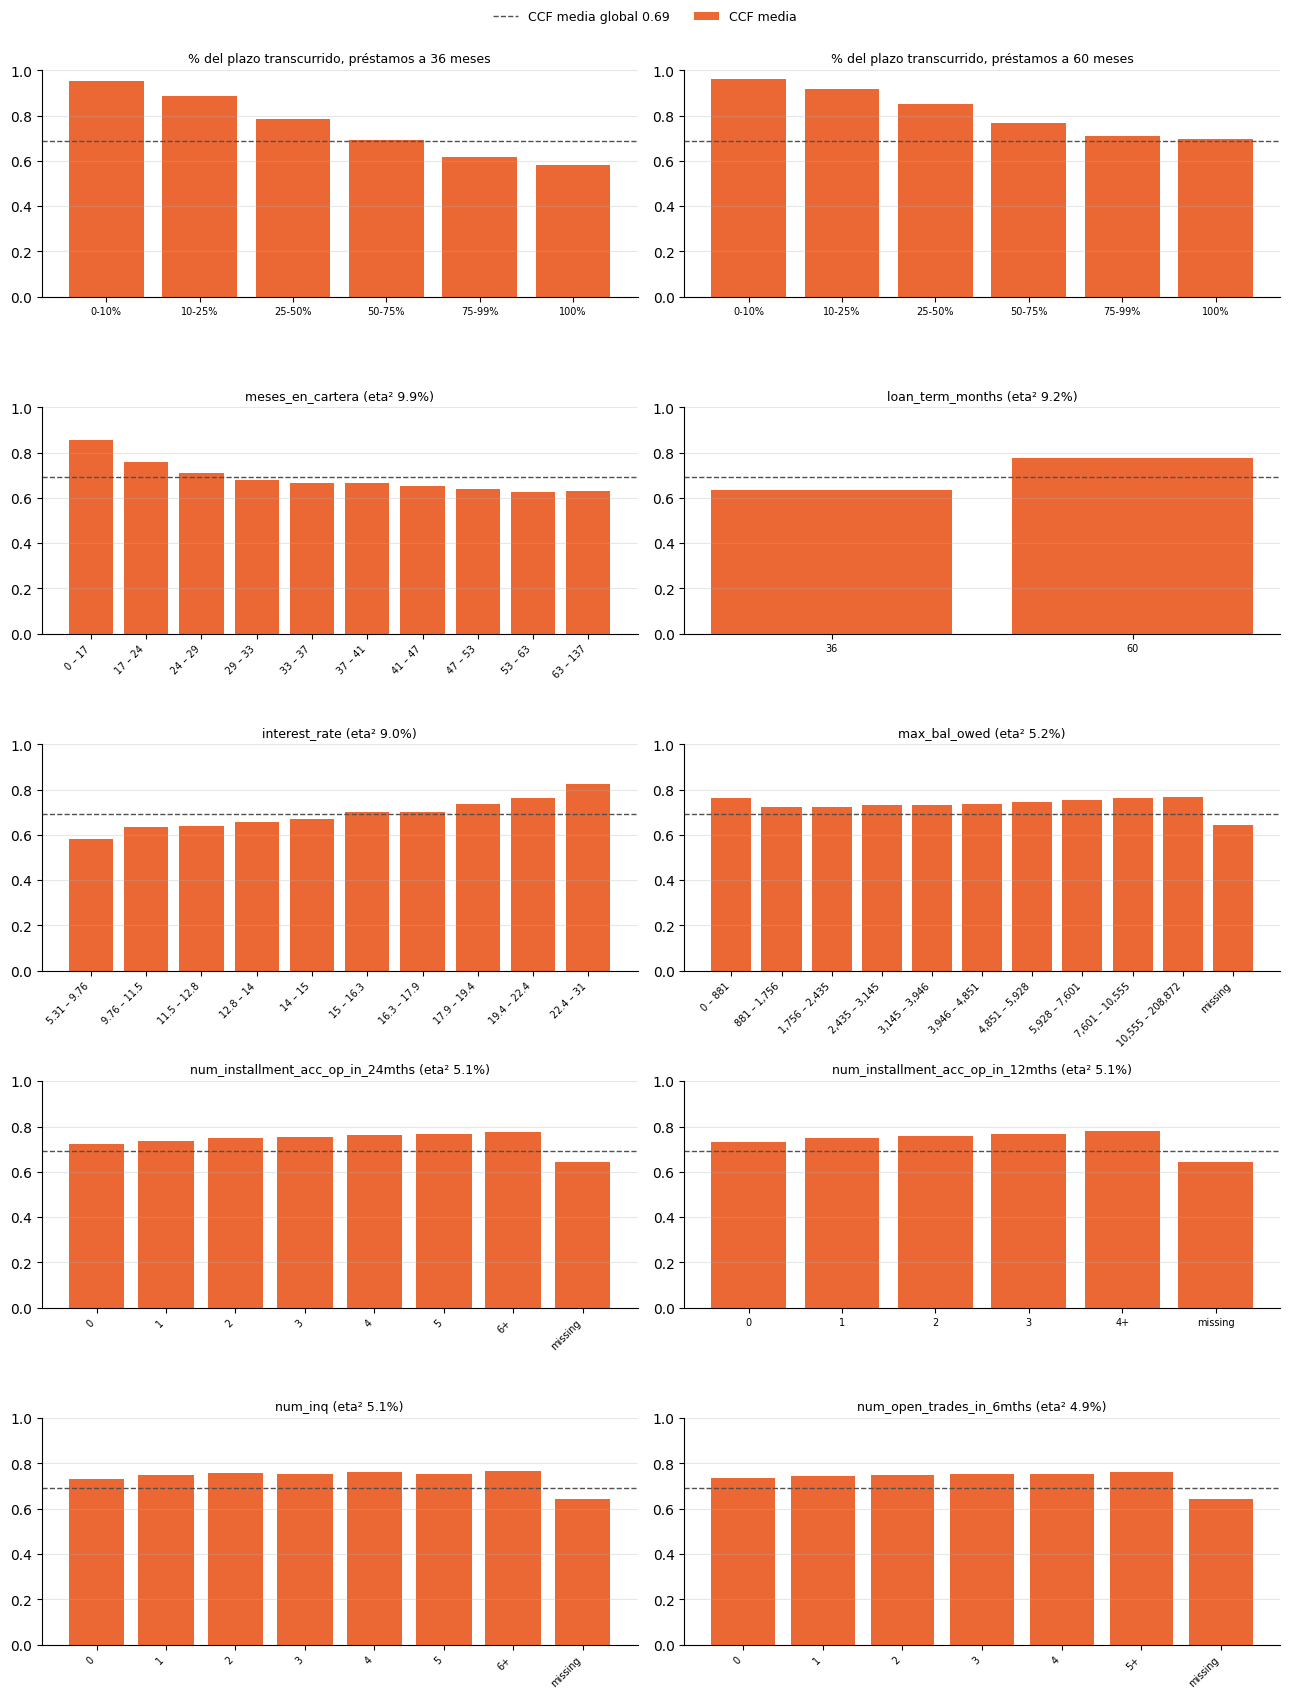

In [10]:
CORTES_MADUREZ = [-0.01, 0.1, 0.25, 0.5, 0.75, 0.99, 1]          # los mismos tramos que en la PD
ETIQUETAS_MADUREZ = ["0-10%", "10-25%", "25-50%", "50-75%", "75-99%", "100%"]


def media_por_grupo(datos, target, grupos):
    """Como tabla_train (5.4 de 01_eda.ipynb), pero para un target continuo: n, media y % sin recobro por grupo."""
    return datos.groupby(grupos.loc[datos.index], observed=True).agg(
        n=(target, "size"), media=(target, "mean"), sin_recobro=("sin_recobro", "mean"))


def plot_media(ax, tabla, titulo, target, media_global, con_recobro=False, max_grupos=15):
    """Barras de la media del target por grupo (eje 0-1); con_recobro añade el % sin recobro."""
    if len(tabla) > max_grupos:                                   # categóricas grandes: los grupos más frecuentes
        tabla = tabla.nlargest(max_grupos, "n").sort_values("media")
        titulo += f" ({max_grupos} más frecuentes)"
    x = np.arange(len(tabla))
    ancho = 0.4 if con_recobro else 0.8
    ax.bar(x - ancho / 2 * con_recobro, tabla["media"], width=ancho, color=COLOR_IMPAGO, label=f"{target} media")
    if con_recobro:
        ax.bar(x + ancho / 2, tabla["sin_recobro"], width=ancho, color=COLOR_REF, label="% sin recobro")
    ax.axhline(media_global, color=COLOR_IMPAGO if con_recobro else COLOR_REF, ls="--", lw=1,
               label=f"{target} media global {media_global:.2f}")
    ax.set_xticks(x, tabla.index.astype(str), rotation=45 if len(tabla) > 6 else 0,
                  ha="right" if len(tabla) > 6 else "center", fontsize=7)
    ax.set_ylim(0, 1)
    ax.set_title(titulo, fontsize=9)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3)


def figura_eda(datos, target, columna_ranking, con_recobro=False):
    """Madurez por plazo (2 paneles) + las 8 variables con más eta² del target."""
    top = [c for c in ranking[columna_ranking].sort_values(ascending=False).index
           if c != "pct_plazo_transcurrido"][:8]
    fig, axes = plt.subplots(5, 2, figsize=(13, 17))
    axes = axes.ravel()
    media_global = datos[target].mean()
    tramo = pd.Series(pd.cut(datos["pct_plazo_transcurrido"], CORTES_MADUREZ, labels=ETIQUETAS_MADUREZ),
                      index=datos.index)
    for ax, plazo in zip(axes, (36, 60)):
        sub = datos[datos["loan_term_months"] == plazo]
        plot_media(ax, media_por_grupo(sub, target, tramo), f"% del plazo transcurrido, préstamos a {plazo} meses",
                   target.upper(), media_global, con_recobro)
    for ax, col in zip(axes[2:], top):
        eta = ranking.loc[col, columna_ranking]
        plot_media(ax, media_por_grupo(datos, target, grupos[col]), f"{col} (eta² {eta:.1f}%)",
                   target.upper(), media_global, con_recobro)
    fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=3, fontsize=9, frameon=False)
    plt.tight_layout(rect=(0, 0, 1, 0.98))
    plt.show()


figura_eda(imp_train, "ccf", "eta² CCF (%)")

### 3.4 LGD frente a las variables más relevantes

**Qué se muestra**: la misma rejilla que en 3.3, pero para la LGD y con los impagados aptos (EAD ≥ 1 €). En cada grupo hay **dos barras**:
- **naranja**: la **LGD media**;
- **gris**: el **% de impagados sin ningún recobro**.

La línea naranja discontinua es la LGD media global.

**Por qué el % sin recobro**: en 2.5 vimos que la LGD es casi binaria. El 37% está en 1 (no se recupera nada) y la mayoría del resto se concentra en un pico alrededor de 0,86. Así que lo que más mueve la LGD media de un grupo es **qué proporción de sus impagados no recupera nada**. Si las dos barras suben y bajan a la vez, la variable actúa sobre todo a través de "hay recobro o no".

**La madurez es clave también aquí**, pero por otro motivo que en el CCF: en los préstamos recientes, el **recobro no ha terminado** (2.5), así que su LGD observada es más alta. Recordatorio importante para el modelo de LGD: la pérdida real de test se mide con la **misma fecha de corte**, así que esos préstamos también tendrán el recobro sin terminar en test. Lo que hay que predecir es la LGD **observada a esa fecha**, y por eso la madurez debe entrar en el modelo.

**Cómo leerlo**: el eje de 0 a 1 hace que las diferencias de LGD parezcan pequeñas. Es lo correcto, porque la LGD varía poco (desviación típica 0,13 frente a 0,22 del CCF). Si incluso las variables más relevantes apenas mueven la barra naranja, unas medias por segmento serán suficientes.

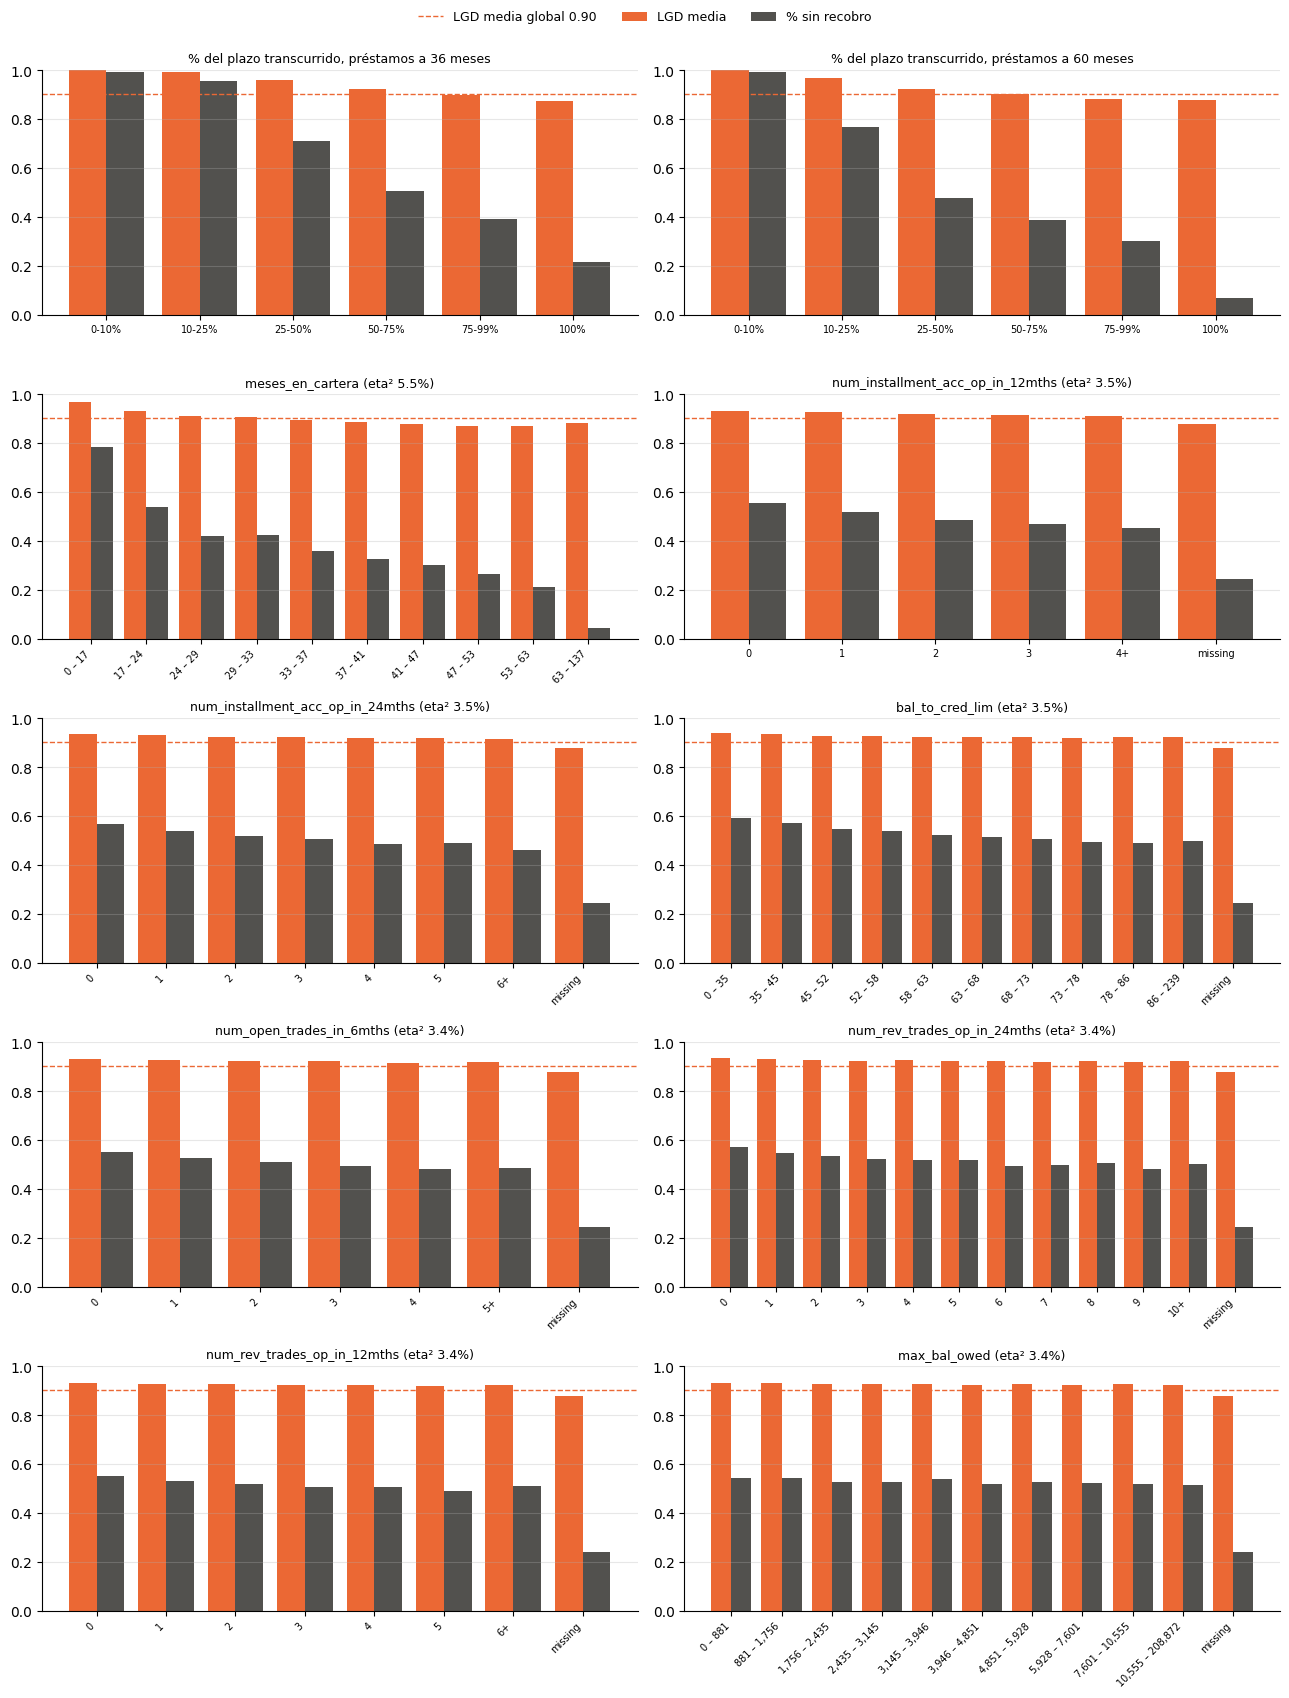

In [11]:
figura_eda(apto, "lgd", "eta² LGD (%)", con_recobro=True)

### 3.5 Conclusiones del EDA del CCF y la LGD

**CCF: tiene señal clara, y la llevan cuatro variables.**
- **Madurez (`pct_plazo_transcurrido`)**, con diferencia la más relevante (eta² 18,5%, Spearman −0,42). En los préstamos a 36 meses, el CCF baja de ~0,95 en los más recientes (0–10% del plazo) a 0,58 en los que ya han cumplido el plazo; a 60 meses, de 0,96 a 0,70. Es lo esperado: un préstamo reciente que ya ha impagado lo ha hecho pronto, sin apenas amortizar.
- **Plazo** (eta² 9,2%): CCF de 0,64 a 36 meses frente a 0,78 a 60 meses, porque a 60 meses se amortiza más despacio.
- **Tipo de interés** (eta² 9,0%): sube de 0,58 en el decil más bajo a 0,82 en el más alto. Con más interés, se amortiza menos principal en cada cuota.
- `meses_en_cartera` (9,9%) es otra forma de medir la madurez.

**Ojo con las variables de buró (eta² ~5% en el CCF y ~3,5% en la LGD).** `max_bal_owed`, `num_inq`, `num_installment_acc_op_*`, `bal_to_cred_lim`, etc. aparecen arriba en el ranking, pero en los gráficos su efecto está **entero en el grupo "missing"**: los demás grupos tienen todos la misma altura y su Spearman es ~0. Ese nulo es el "bloque del 40%" de 3.5 de `01_eda.ipynb`: préstamos de 2015 o antes, en los que el dato no existía. Es decir, **es la madurez encubierta**, no información del buró. No aporta nada que no dé ya `pct_plazo_transcurrido`. Para el modelo no es un problema, porque el árbol usará la madurez directamente.

**LGD: poca variación en la media, pero un patrón muy fuerte en "hay recobro o no".**
- La LGD media apenas se mueve: de ~1,0 en los préstamos más recientes a ~0,87 en los que han cumplido el plazo. Ninguna variable de perfil del cliente (ingresos, finalidad, profesión, estado, DTI...) llega a un eta² del 0,5%.
- Lo que sí cambia muchísimo es el **% sin recobro**, y **solo con la madurez**: del 99% en los préstamos a 36 meses con un 0–10% del plazo transcurrido al 21% en los vencidos (del 100% al 7% a 60 meses). No es que los clientes recientes sean peores pagadores tras el impago: es que **todavía no ha dado tiempo a recobrar** (2.5).
- Cuando hay recobro, ronda el 10–15% de la EAD (el pico en LGD ≈ 0,86 de 2.5), con poca variación. Por eso, aunque el % sin recobro cambie tanto, la LGD media solo se mueve entre 0,87 y 1.

**Qué implica para los modelos:**
- **EAD (sección 4)**: hay señal suficiente para que un LightGBM aporte frente a las medias por segmento. Como referencia sencilla usaremos **plazo × tramo de madurez**, que ya recoge las dos variables principales. El tipo de interés debería ser la principal ganancia del modelo. Métricas: **MAE del CCF** y **MAE de la EAD en euros**, con el CCF sin pesos frente al CCF ponderado por `funded_amnt`.
- **LGD (sección 5)**: la señal es casi solo la madurez. Lo más probable es que unas **medias por plazo × tramo de madurez** queden muy cerca de un LightGBM, y serían más estables y fáciles de explicar. Lo comprobaremos en validación antes de decidir.
- **La madurez debe entrar en los dos modelos**, igual que en la PD. En test la pérdida real se mide con la misma fecha de corte, así que hay que predecir el CCF y la LGD **observados a esa fecha**, incluido el recobro sin terminar de los préstamos recientes.

## 4. Modelo de EAD (target: CCF)

El modelo de EAD predice **cuánto se deberá en el momento del impago**. Como vimos al construir los targets, se entrena con el **CCF** (EAD / importe financiado) y la EAD en euros se recupera multiplicando:

EAD_i = CCF_i (predicho) × funded_amnt_i

El importe se conoce desde la concesión, así que este paso no añade error.

**Datos**:
- **entrenamiento**: los **impagados de train** (179.018), porque solo en ellos se observa la EAD;
- **evaluación**: los **impagados de validación** (44.755);
- test no se toca.

**Predictores**: las 40 candidatas de 3.1, las mismas que en la PD.

**Plan de la sección:**
1. Preprocesador y datos (4.1).
2. Métricas (4.2).
3. Referencias sin modelo: media global y medias por segmento (4.3).
4. LightGBM, sin pesos y ponderado por importe (4.4).
5. Comparación (4.5).
6. Modelo final (4.6).

### 4.1 Datos y preprocesador

**Qué hace**: separa los impagados de validación y construye `preproc_ead`, un `ColumnTransformer` que convierte las 40 candidatas en una matriz numérica para LightGBM:

| Rama | Variables | Tratamiento |
|---|---|---|
| Numéricas | 16 continuas, 11 conteos, 4 nuevas y el plazo | **Tal cual** |
| Categóricas pequeñas | vivienda, verificación, listado, desembolso, región, finalidad, estado | **One-hot** (`handle_unknown="ignore"`) |
| Profesión | `emp_title_clean` (207 categorías) | **`TargetEncoder`** para target continuo: el CCF medio de cada profesión, suavizado |

**Por qué no se imputan los nulos** (en la PD sí se hizo, con `ImputadorConFlag`):
- LightGBM **gestiona los nulos de forma nativa**: en cada corte aprende hacia qué lado mandar los préstamos con NaN.
- En 3.5 vimos que los nulos del "bloque del 40%" equivalen a la madurez. Dejarlos como NaN conserva esa información sin inventar valores.
- Es un preprocesado más simple, y en este modelo no hay logística que necesite valores completos.

El `ColumnTransformer` se crea con una función, `crear_preproc()`, porque el modelo de LGD (sección 5) usará el mismo esquema reajustado con su propio target.

**Sin fuga de información**: el preprocesador se ajusta **solo con los impagados de train**. El `TargetEncoder` aprende del CCF, así que usa **validación cruzada interna** (5 trozos): la codificación de cada préstamo de train se calcula sin ese préstamo, como en la PD. Después se aplica tal cual a validación.

**Cómo leer la salida**: el número de columnas de cada rama. Los asserts garantizan que no quedan columnas de texto y que train y validación tienen las mismas columnas.

In [12]:
import time
import lightgbm as lgb
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, TargetEncoder

imp_val = val[val["impago"] == 1].copy()

cats_pequenas = [c for c in cats_cand if c not in ("loan_term_months", "emp_title_clean")]   # el plazo es numérico
num_ead = [c for c in candidatas if c not in cats_pequenas + ["emp_title_clean"]]


def crear_preproc():
    """Preprocesador para LightGBM con target continuo (se usa para la EAD y, en la sección 5, para la LGD)."""
    return ColumnTransformer([
        ("num", "passthrough", num_ead),                                     # LightGBM gestiona los NaN
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cats_pequenas),
        ("emp_title", TargetEncoder(target_type="continuous", cv=KFold(5, shuffle=True, random_state=42)),
         ["emp_title_clean"]),
    ], verbose_feature_names_out=False).set_output(transform="pandas")


preproc_ead = crear_preproc()

# Ajuste SOLO con los impagados de train; validación solo se transforma
X_ead_train = preproc_ead.fit_transform(imp_train[candidatas], imp_train["ccf"])
X_ead_val = preproc_ead.transform(imp_val[candidatas])

# Comprobaciones
assert X_ead_train.index.equals(imp_train.index) and X_ead_val.index.equals(imp_val.index), "Cambian las filas"
assert all(pd.api.types.is_numeric_dtype(t) for t in X_ead_train.dtypes), "Quedan columnas no numéricas"
assert list(X_ead_train.columns) == list(X_ead_val.columns), "Train y validación tienen columnas distintas"
ramas = {r: len(t.get_feature_names_out()) for r, t, _ in preproc_ead.transformers_ if r != "remainder"}
print(f"Impagados: train {len(imp_train):,} | validación {len(imp_val):,}")
print(f"Columnas: {X_ead_train.shape[1]} -> {ramas}")

Impagados: train 179,018 | validación 44,755
Columnas: 119 -> {'num': 32, 'cat': 86, 'emp_title': 1}


### 4.2 Métricas de evaluación

Para cada modelo calculamos tres métricas sobre los **impagados de validación**:

| Métrica | Fórmula | Qué mide |
|---|---|---|
| **MAE_ccf** | media de \|CCF predicho − CCF real\| | Error medio en **proporción del préstamo**. Comparable entre préstamos de cualquier tamaño |
| **MAE_euros** | media de \|EAD predicha − EAD real\|, con EAD predicha = CCF predicho × funded_amnt | Error medio **en euros**. Es la que importa para el ECL, porque el ECL se evalúa en euros |
| **Σ EAD estimada / Σ EAD real** | suma de las EAD predichas / suma de las reales | **Calibración global**: 1 = exacto, > 1 = sobreestima (conservador), < 1 = subestima |

**Por qué las dos MAE.** Un modelo puede acertar mucho en proporción y fallar en euros si se equivoca justo en los préstamos grandes: un 10% de error en un préstamo de 35.000 € son 3.500 €, y en uno de 2.000 € son 200 €. Comparar MAE_ccf y MAE_euros dice si la ponderación por importe (4.4) consigue **mover el error hacia los préstamos pequeños**, que es lo que interesa para el ECL en euros.

**Por qué la MAE y no el error cuadrático**: la MAE se lee directamente en las mismas unidades que el target (proporción o euros) y es la métrica con la que se evalúa el ECL (criterio 3, en `01_eda.ipynb`). El error cuadrático daría mucho peso a unos pocos errores grandes.

Los resultados se guardan en `resultados_ead`, una fila por modelo.

In [13]:
def evaluar_ead(datos, ccf_pred):
    """MAE_ccf, MAE_euros y calibración global de la EAD sobre unos impagados con target observado."""
    ccf_pred = np.asarray(ccf_pred)
    ead_pred = ccf_pred * datos["funded_amnt"].to_numpy()
    return {"MAE_ccf": np.abs(ccf_pred - datos["ccf"].to_numpy()).mean(),
            "MAE_euros": np.abs(ead_pred - datos["ead"].to_numpy()).mean(),
            "Σ EAD estimada / real": ead_pred.sum() / datos["ead"].sum()}


resultados_ead, ccf_pred_val = {}, {}     # métricas y CCF predicho en los impagados de validación, por modelo
print(f"EAD real media en los impagados de validación: {imp_val['ead'].mean():,.0f} € "
      f"(CCF medio {imp_val['ccf'].mean():.3f})")

EAD real media en los impagados de validación: 11,024 € (CCF medio 0.689)


### 4.3 Referencias sin modelo: media global y medias por segmento

Antes de entrenar LightGBM fijamos dos **referencias** que cualquier modelo debe batir:

1. **Media global**: el mismo CCF para todos, la media de los impagados de train (~0,69). Es el equivalente al "modelo ingenuo" de la PD: lo que se haría sin ninguna variable.
2. **Medias por plazo × tramo de madurez**: 2 plazos × 6 tramos de `pct_plazo_transcurrido` (los mismos de la PD) = 12 segmentos. Cada préstamo recibe el CCF medio de su segmento en train.
   - Recoge las **dos variables principales del EDA** (3.5): la madurez y el plazo.
   - Es un "modelo" muy simple, transparente y estable, y es un enfoque habitual en los modelos de LGD y EAD.
   - Si LightGBM no lo mejora claramente, habría que plantearse quedarse con él.

**Qué hace la celda**: calcula las medias con los impagados de train, las aplica a validación y añade las dos filas a `resultados_ead`. Muestra también la tabla de las 12 medias.

**Cómo leer la tabla de medias**: filas = plazo, columnas = tramo de madurez. Debería reproducir lo que vimos en 3.3: el CCF baja al aumentar la madurez y es más alto a 60 meses.

In [14]:
def tramo_madurez(datos):
    return pd.cut(datos["pct_plazo_transcurrido"], CORTES_MADUREZ, labels=ETIQUETAS_MADUREZ)


def clave_segmento(datos):
    """Segmento plazo × tramo de madurez como texto, p. ej. '36 | 25-50%'."""
    return datos["loan_term_months"].astype(str) + " | " + tramo_madurez(datos).astype(str)


# 1) Media global de train
ccf_medio = imp_train["ccf"].mean()
ccf_pred_val["Media global"] = np.full(len(imp_val), ccf_medio)

# 2) Medias por segmento, aprendidas en train (un segmento sin datos en train recibiría la media global)
medias_segmento = imp_train.groupby(clave_segmento(imp_train))["ccf"].mean()
ccf_pred_val["Medias plazo × madurez"] = clave_segmento(imp_val).map(medias_segmento).fillna(ccf_medio).to_numpy()

for nombre in ("Media global", "Medias plazo × madurez"):
    resultados_ead[nombre] = evaluar_ead(imp_val, ccf_pred_val[nombre])

print("CCF medio por segmento en los impagados de train:")
display(imp_train.groupby([imp_train["loan_term_months"].rename("plazo"),
                           tramo_madurez(imp_train).rename("% plazo transcurrido")], observed=True)["ccf"]
        .mean().unstack().round(3))
pd.DataFrame(resultados_ead).T.round(4)

CCF medio por segmento en los impagados de train:


% plazo transcurrido,0-10%,10-25%,25-50%,50-75%,75-99%,100%
plazo,,,,,,
36,0.953,0.887,0.784,0.690,0.616,0.580
60,0.963,0.916,0.851,0.768,0.709,0.696


,MAE_ccf,MAE_euros,Σ EAD estimada / real
Media global,0.1805,2748.7825,0.9720
Medias plazo × madurez,0.1561,2301.5157,0.9962


### 4.4 LightGBM: CCF sin pesos y ponderado por importe

**El modelo**: `LGBMRegressor(objective="cross_entropy")`.
- El objetivo `cross_entropy` es el log-loss de la PD, pero admite un **target continuo entre 0 y 1**: trata cada CCF como una "probabilidad" y la predice con una función logística.
- Ventaja clave: **la predicción siempre está entre 0 y 1**, así que se garantiza 0 ≤ EAD ≤ importe prestado, que es lo que pasa en la realidad. Una regresión normal (error cuadrático) podría predecir CCF negativos o mayores que 1.

**Hiperparámetros**: los mismos de la PD (5.4 de `02_modelo_pd.ipynb`), que ya resultaron robustos. El número de árboles lo decide el **early stopping**: se para cuando 50 árboles seguidos no mejoran el error en los impagados de validación, con un máximo de 3.000. Igual que en la PD, validación se usa para el early stopping, no para entrenar. Con 179.000 impagados el ajuste tarda poco y no hace falta trabajar con una muestra.

**Las dos versiones:**

| Versión | `sample_weight` | Qué optimiza |
|---|---|---|
| **Sin pesos** | — | Todos los préstamos pesan igual: minimiza el error **en proporción** |
| **Ponderado por importe** | `funded_amnt` | Un préstamo de 30.000 € pesa 10 veces más que uno de 3.000 €: minimiza el error **en euros** |

Con pesos, el modelo se esfuerza más en acertar el CCF de los préstamos grandes, que son los que más euros de EAD (y de ECL) mueven. El early stopping también se pondera (`eval_sample_weight`), para que elija el número de árboles con el mismo criterio.

**Qué esperamos**: el ponderado debería tener un **MAE_euros algo menor** y un **MAE_ccf algo mayor** que el sin pesos. Si la diferencia es pequeña, significa que la relación entre el CCF y las variables es parecida en préstamos grandes y pequeños.

**Cómo leer la salida**: la tabla con las cuatro filas (las dos referencias y los dos LightGBM), el número de árboles y los segundos de ajuste.

In [15]:
PARAMS_LGBM = dict(n_estimators=3000, learning_rate=0.05, num_leaves=31, min_child_samples=100,
                   subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1,
                   random_state=42, verbose=-1)               # los de la PD (5.4 de 02_modelo_pd.ipynb)

modelos_ead = {}
for nombre, pesos in (("LightGBM sin pesos", None), ("LightGBM ponderado por importe", "funded_amnt")):
    t0 = time.time()
    lgbm = lgb.LGBMRegressor(objective="cross_entropy", **PARAMS_LGBM)
    lgbm.fit(X_ead_train, imp_train["ccf"],
             sample_weight=None if pesos is None else imp_train[pesos],
             eval_X=X_ead_val, eval_y=imp_val["ccf"],
             eval_sample_weight=None if pesos is None else [imp_val[pesos]],
             callbacks=[lgb.early_stopping(50, verbose=False)])
    pred = lgbm.predict(X_ead_val)
    assert ((pred >= 0) & (pred <= 1)).all(), "CCF predicho fuera de [0, 1]"

    modelos_ead[nombre] = Pipeline([("prep", preproc_ead), ("modelo", lgbm)])   # columnas originales -> CCF
    ccf_pred_val[nombre] = pred
    resultados_ead[nombre] = {**evaluar_ead(imp_val, pred), "árboles": lgbm.best_iteration_,
                              "segundos": round(time.time() - t0)}

pd.DataFrame(resultados_ead).T.astype(float).round(4)

,MAE_ccf,MAE_euros,Σ EAD estimada / real,árboles,segundos
Media global,0.1805,2748.7825,0.9720,NaN,NaN
Medias plazo × madurez,0.1561,2301.5157,0.9962,NaN,NaN
LightGBM sin pesos,0.1493,2184.8079,1.0002,293.0,6.0
LightGBM ponderado por importe,0.1494,2185.4674,1.0000,250.0,5.0


### 4.5 Comparación de los modelos de EAD

**1) Tabla resumen**: las cuatro filas, con la mejora de cada modelo frente a la media global en MAE_euros (%). La métrica principal es la **MAE_euros**, porque el ECL se mide en euros.

**2) Calibración por grupos**: Σ EAD estimada / Σ EAD real dentro de cada grupo, para las medias por segmento y los dos LightGBM. Un buen MAE global puede esconder errores sistemáticos en algún grupo, por ejemplo infraestimar siempre los préstamos grandes. Se mira:
- **por plazo** y **por tramo de madurez**: las dos variables clave del EDA;
- **por deciles de importe**: es donde debería notarse la ponderación. El modelo sin pesos podría equivocarse más en los préstamos grandes.

Cómo leerlo: valores cercanos a 1 en todas las filas = bien calibrado. Por debajo de 1 = infraestima la EAD de ese grupo (la dirección peligrosa: infraprovisionar).

**3) Calibración por deciles del CCF predicho** del mejor LightGBM: los impagados de validación ordenados por su CCF predicho y partidos en 10 grupos, comparando el CCF medio predicho (azul) con el observado (naranja), como en la calibración de la PD (7.2 de `02_modelo_pd.ipynb`). Si las barras tienen la misma altura, el modelo acierta en todo el rango de CCF.

**4) Importancia de las variables (gain)** del mejor LightGBM, sumada por variable original (las columnas one-hot de una misma variable se suman). Es el % de la mejora total del ajuste que aporta cada variable. Esperamos arriba la madurez, el plazo y el tipo de interés (3.5).

,MAE_ccf,MAE_euros,Σ EAD estimada / real,árboles,segundos,mejora MAE_euros vs media (%)
Media global,0.1805,2748.7825,0.9720,NaN,NaN,0.0000
Medias plazo × madurez,0.1561,2301.5157,0.9962,NaN,NaN,16.2715
LightGBM sin pesos,0.1493,2184.8079,1.0002,293.0,6.0,20.5172
LightGBM ponderado por importe,0.1494,2185.4674,1.0000,250.0,5.0,20.4933


Mejor LightGBM por MAE_euros: LightGBM sin pesos

Σ EAD estimada / Σ EAD real por plazo:


,n,EAD real media (€),Medias plazo × madurez,LightGBM sin pesos,LightGBM ponderado por importe
plazo,,,,,
36,27276,8109.0,0.994,1.0,1.0
60,17479,15572.0,0.998,1.0,1.0


Σ EAD estimada / Σ EAD real por tramo de madurez:


,n,EAD real media (€),Medias plazo × madurez,LightGBM sin pesos,LightGBM ponderado por importe
% plazo transcurrido,,,,,
0-10%,335,18388.0,1.002,0.998,0.998
10-25%,1962,16770.0,1.000,0.998,0.999
25-50%,6004,14261.0,0.999,1.001,1.001
50-75%,10791,12964.0,0.996,1.003,1.002
75-99%,9525,10446.0,0.989,0.995,0.996
100%,16138,8011.0,0.999,1.001,1.001


Σ EAD estimada / Σ EAD real por decil de importe:


,n,EAD real media (€),Medias plazo × madurez,LightGBM sin pesos,LightGBM ponderado por importe
importe,,,,,
"(499.999, 5000.0]",4789,2400.0,1.002,1.003,1.005
"(5000.0, 7875.0]",4170,4083.0,1.002,1.000,1.000
"(7875.0, 10000.0]",6651,6067.0,1.006,0.997,0.996
"(10000.0, 12000.0]",4434,7860.0,1.020,1.013,1.014
"(12000.0, 14225.0]",2338,9347.0,0.998,1.004,1.004
"(14225.0, 16000.0]",4946,10660.0,1.006,0.998,0.998
"(16000.0, 20000.0]",6105,13387.0,0.998,0.997,0.997
"(20000.0, 23850.0]",2383,15601.0,1.000,1.011,1.011
"(23850.0, 29700.0]",4473,18746.0,0.997,1.002,1.003


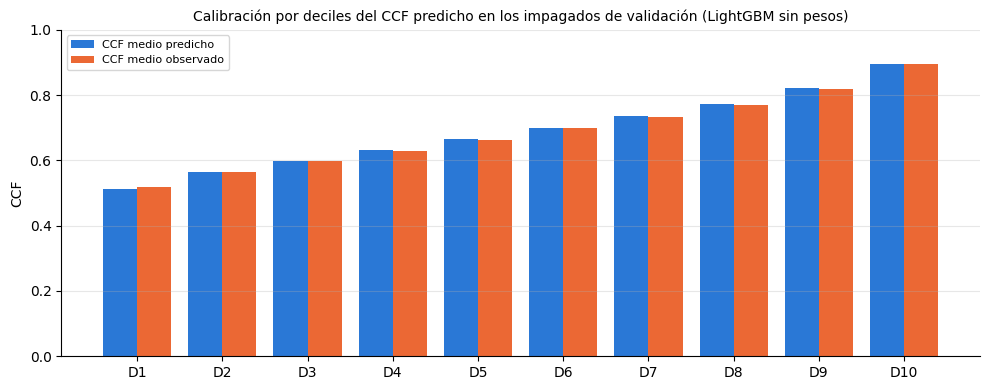

,% gain
pct_plazo_transcurrido,47.5
interest_rate,14.4
loan_term_months,12.3
meses_en_cartera,10.7
used_credit_share,1.1
total_credit_revolving_bal,1.1
credit_hist_years,0.8
mths_since_last_installment_acc_op,0.8
dept_paym_income_ratio,0.8
funded_amnt,0.8


In [16]:
# 1) Tabla resumen
tabla_ead = pd.DataFrame(resultados_ead).T.astype(float)
tabla_ead["mejora MAE_euros vs media (%)"] = 100 * (1 - tabla_ead["MAE_euros"] / tabla_ead.loc["Media global", "MAE_euros"])
display(tabla_ead.round(4))
mejor_lgbm = min(modelos_ead, key=lambda n: resultados_ead[n]["MAE_euros"])
print(f"Mejor LightGBM por MAE_euros: {mejor_lgbm}\n")

# 2) Calibración por grupos: Σ EAD estimada / Σ EAD real
comparar = ["Medias plazo × madurez", "LightGBM sin pesos", "LightGBM ponderado por importe"]


def calibracion_ead(grupo):
    t = pd.DataFrame({"n": imp_val.groupby(grupo, observed=True).size(),
                      "EAD real media (€)": imp_val.groupby(grupo, observed=True)["ead"].mean()})
    ead_real = imp_val["ead"].groupby(grupo, observed=True).sum()
    for nombre in comparar:
        ead_pred = pd.Series(ccf_pred_val[nombre] * imp_val["funded_amnt"].to_numpy(), index=imp_val.index)
        t[nombre] = ead_pred.groupby(grupo, observed=True).sum() / ead_real
    return t


for titulo, grupo in (("plazo", imp_val["loan_term_months"].rename("plazo")),
                      ("tramo de madurez", tramo_madurez(imp_val).rename("% plazo transcurrido")),
                      ("decil de importe", pd.qcut(imp_val["funded_amnt"], 10, duplicates="drop").rename("importe"))):
    print(f"Σ EAD estimada / Σ EAD real por {titulo}:")
    display(calibracion_ead(grupo).round({"EAD real media (€)": 0}).round(3))

# 3) Calibración por deciles del CCF predicho (mejor LightGBM)
pred_mejor = pd.Series(ccf_pred_val[mejor_lgbm], index=imp_val.index)
decil = pd.qcut(pred_mejor, 10, labels=[f"D{i}" for i in range(1, 11)])
calib_ccf = pd.DataFrame({"CCF predicho": pred_mejor.groupby(decil, observed=True).mean(),
                          "CCF observado": imp_val["ccf"].groupby(decil, observed=True).mean()})
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(calib_ccf))
ax.bar(x - 0.2, calib_ccf["CCF predicho"], width=0.4, color=COLOR_NO_IMPAGO, label="CCF medio predicho")
ax.bar(x + 0.2, calib_ccf["CCF observado"], width=0.4, color=COLOR_IMPAGO, label="CCF medio observado")
ax.set_xticks(x, calib_ccf.index)
ax.set_ylim(0, 1)
ax.set_ylabel("CCF")
ax.set_title(f"Calibración por deciles del CCF predicho en los impagados de validación ({mejor_lgbm})", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

# 4) Importancia (gain) sumada por variable original
gain = pd.Series(modelos_ead[mejor_lgbm].named_steps["modelo"].booster_.feature_importance("gain"),
                 index=X_ead_train.columns)
origen = [c if c in candidatas else max((v for v in candidatas if c.startswith(v + "_")), key=len)
          for c in X_ead_train.columns]
(gain.groupby(origen).sum() / gain.sum() * 100).sort_values(ascending=False).head(12).round(1).to_frame("% gain")

### 4.6 Modelo de EAD final

**Resultados de 4.4 y 4.5** (impagados de validación):

| Modelo | MAE_ccf | MAE_euros | Σ EAD est. / real | Mejora MAE_euros vs media |
|---|---|---|---|---|
| Media global | 0,1805 | 2.749 € | 0,972 | — |
| Medias plazo × madurez | 0,1561 | 2.302 € | 0,996 | 16,3% |
| **LightGBM sin pesos** | **0,1493** | **2.185 €** | **1,000** | **20,5%** |
| LightGBM ponderado por importe | 0,1494 | 2.185 € | 1,000 | 20,5% |

**Qué nos dice:**
- **Los segmentos ya consiguen la mayor parte de la mejora** (16 de los 20,5 puntos). Plazo y madurez explican casi todo lo que se puede explicar del CCF, como anticipaba el EDA.
- **LightGBM añade otro ~5% sobre los segmentos** (117 € menos de error medio por impagado). Viene sobre todo del **tipo de interés**: es la segunda variable en importancia (14%), detrás de la madurez (`pct_plazo_transcurrido` 47% + `meses_en_cartera` 11%) y por delante del plazo (12%). El resto de variables aportan un 1% o menos cada una.
- **Ponderar por importe no cambia nada**: 0,7 € de diferencia en MAE_euros y la misma calibración en todos los deciles de importe. La relación entre el CCF y las variables es la misma en préstamos grandes y pequeños, así que dar más peso a los grandes no enseña nada nuevo al modelo. Nos quedamos con el **sin pesos**: es igual de bueno y más simple.
- **Calibración excelente**:
  - Σ EAD estimada / real = 1,000 global;
  - entre 0,995 y 1,003 por plazo y por tramo de madurez;
  - entre 0,995 y 1,013 por decil de importe;
  - por deciles del CCF predicho, las barras azul y naranja son prácticamente iguales.

  Además, el modelo corrige el único sesgo visible de los segmentos: infraestimaban un 2,5% los préstamos más grandes (0,975 en el último decil de importe, frente a 0,995 de LightGBM).
- **El MAE sigue siendo grande en términos absolutos** (~2.200 €, un 20% de la EAD media). Es inevitable: el momento exacto del impago, que es lo que fija el CCF, no se puede saber en la concesión. Para el ECL lo que importa es que **no haya sesgo**, y no lo hay.

**Elegido: LightGBM sin pesos.** No hace falta ajustar hiperparámetros: el modelo se para en menos de 300 árboles, la calibración es perfecta, y en la PD el ajuste fino no aportó nada.

**Qué hace la celda**: guarda el modelo final como `modelo_ead`, un `Pipeline` que recibe las columnas originales y devuelve el CCF. Lo aplica a **todos** los préstamos de validación, impagados o no, porque el ECL se calcula sobre toda la cartera. Para un préstamo que no ha impagado, la EAD predicha es "cuánto debería si impagara". Guarda `ccf_val` y `ead_val` (en €) para la sección del ECL.

**Cómo leer la salida**: CCF y EAD predichos medios en los impagados y en los no impagados de validación.

**Resultado**: en los no impagados, el CCF predicho medio es algo **más alto** (0,71 frente a 0,69). Tiene sentido: entre los no impagados hay más préstamos **recientes**, que todavía no han tenido tiempo de impagar. Si un préstamo reciente impagara, lo haría pronto y con mucho principal pendiente, y por eso su CCF predicho es alto. La EAD total predicha de validación es de ~3.665 M€ (3.171 M€ en los no impagados y 493 M€ en los impagados). Entrará en el ECL multiplicada por la PD y la LGD.

In [17]:
elegido_ead = "LightGBM sin pesos"
assert elegido_ead == mejor_lgbm, "El mejor LightGBM por MAE_euros no es el elegido: revisar 4.5"
modelo_ead = modelos_ead[elegido_ead]     # Pipeline: columnas originales -> CCF

# CCF y EAD (€) de TODOS los préstamos de validación: el ECL se calcula sobre toda la cartera
ccf_val = pd.Series(modelo_ead.predict(val[candidatas]), index=val.index, name="ccf_pred")
ead_val = (ccf_val * val["funded_amnt"]).rename("ead_pred")

# Comprobaciones
assert ccf_val.between(0, 1).all(), "CCF predicho fuera de [0, 1]"
assert np.allclose(ccf_val.loc[imp_val.index], ccf_pred_val[elegido_ead]), "No coincide con la evaluación de 4.4"

pd.DataFrame({
    "n": val.groupby("impago").size(),
    "CCF predicho medio": ccf_val.groupby(val["impago"]).mean(),
    "EAD predicha media (€)": ead_val.groupby(val["impago"]).mean(),
    "Σ EAD predicha (M€)": ead_val.groupby(val["impago"]).sum() / 1e6,
}).rename(index={0: "no impago", 1: "impago"}).round(3)

,n,CCF predicho medio,EAD predicha media (€),Σ EAD predicha (M€)
impago,,,,
no impago,297588,0.71,10656.969,3171.386
impago,44755,0.69,11026.006,493.469


## 5. Modelo de LGD

El modelo de LGD predice **qué parte de la EAD no se recupera nunca** (LGD = 1 − recobros / EAD, entre 0 y 1). Con él se completa el ECL:

ECL_i = PD_i × LGD_i × EAD_i

**Datos**:
- **entrenamiento**: los impagados de train **aptos** (`apto_lgd`: EAD ≥ 1 €, 178.958). Los 60 con EAD ≈ 0 no tienen una LGD definida (2.2);
- **evaluación**: los impagados aptos de validación;
- test no se toca.

**Predictores**: las 40 candidatas, como en la PD y en la EAD.

**Qué esperamos, por el EDA (3.4 y 3.5)**: la LGD varía poco (desviación típica 0,13) y casi solo con la **madurez**. En los préstamos recientes el recobro no ha terminado, así que su LGD observada es ~1. Ninguna variable del perfil del cliente llega a un eta² del 0,5%. Así que lo más probable es que unas **medias por segmento** queden muy cerca de LightGBM. La sección tiene la misma estructura que la 4 para comparar en igualdad de condiciones.

**Recordatorio importante**: la pérdida real de test se mide con la **misma fecha de corte** (2018-12-01), así que en test los préstamos recientes también tendrán el recobro sin terminar. Lo que hay que predecir es la LGD **observada a esa fecha**, y por eso la madurez es un predictor legítimo y necesario.

### 5.1 Datos y preprocesador

**Qué hace**: separa los impagados aptos de validación y crea `preproc_lgd` con la misma función que en la EAD (`crear_preproc()`: numéricas tal cual, one-hot y `TargetEncoder`).

**Por qué un preprocesador nuevo y no reutilizar `preproc_ead`**: el `TargetEncoder` de `emp_title_clean` codifica cada profesión con la **media del target**. En `preproc_ead` esa media es el CCF; aquí tiene que ser la **LGD**. El resto de piezas (one-hot, numéricas) no aprenden del target, pero es más limpio reajustar todo el preprocesador junto.

**Sin fuga**: se ajusta solo con los impagados aptos de train, con validación cruzada interna en el `TargetEncoder`.

**Cómo leer la salida**: tamaños de los dos conjuntos y número de columnas. Debe dar las mismas 119 columnas que en la EAD.

In [18]:
apto_val = imp_val[imp_val["apto_lgd"]].copy()

preproc_lgd = crear_preproc()
X_lgd_train = preproc_lgd.fit_transform(apto[candidatas], apto["lgd"])     # SOLO impagados aptos de train
X_lgd_val = preproc_lgd.transform(apto_val[candidatas])

# Comprobaciones
assert X_lgd_train.index.equals(apto.index) and X_lgd_val.index.equals(apto_val.index), "Cambian las filas"
assert all(pd.api.types.is_numeric_dtype(t) for t in X_lgd_train.dtypes), "Quedan columnas no numéricas"
assert list(X_lgd_train.columns) == list(X_lgd_val.columns) == list(X_ead_train.columns)
assert apto["lgd"].notna().all() and apto_val["lgd"].notna().all()
print(f"Impagados aptos: train {len(apto):,} | validación {len(apto_val):,} "
      f"({(~imp_val['apto_lgd']).sum()} de validación con EAD < 1 € fuera)")
print(f"Columnas: {X_lgd_train.shape[1]}")

Impagados aptos: train 178,958 | validación 44,737 (18 de validación con EAD < 1 € fuera)
Columnas: 119


### 5.2 Métricas de evaluación

Las mismas ideas que en la EAD, adaptadas a la LGD y calculadas sobre los **impagados aptos de validación**:

| Métrica | Fórmula | Qué mide |
|---|---|---|
| **MAE_lgd** | media de \|LGD predicha − LGD real\| | Error medio en **proporción de la EAD** |
| **MAE_euros** | media de \|LGD predicha × EAD real − pérdida real\| | Error medio de la **pérdida en euros** |
| **Σ pérdida estimada / Σ pérdida real** | suma de LGD predicha × EAD real / suma de pérdidas reales | **Calibración global**: 1 = exacto, > 1 = conservador |

**Por qué se multiplica por la EAD real y no por la predicha**: queremos medir **solo el error de la LGD**. Con la EAD predicha, el error del modelo de EAD se mezclaría con el de la LGD y no sabríamos cuál de los dos falla. El error combinado PD × LGD × EAD se medirá en la sección del ECL.

**Por qué la MAE_euros importa más**: acertar la LGD de un impagado con 30.000 € de EAD vale mucho más, para el ECL, que acertar la de uno con 1.000 €. La MAE_euros lo tiene en cuenta; la MAE_lgd no.

In [19]:
def evaluar_lgd(datos, lgd_pred):
    """MAE_lgd, MAE_euros (pérdida = LGD × EAD real) y calibración global de la pérdida."""
    lgd_pred = np.asarray(lgd_pred)
    perdida_pred = lgd_pred * datos["ead"].to_numpy()
    return {"MAE_lgd": np.abs(lgd_pred - datos["lgd"].to_numpy()).mean(),
            "MAE_euros": np.abs(perdida_pred - datos["perdida_real"].to_numpy()).mean(),
            "Σ pérdida estimada / real": perdida_pred.sum() / datos["perdida_real"].sum()}


resultados_lgd, lgd_pred_val = {}, {}
print(f"Pérdida real media en los impagados aptos de validación: {apto_val['perdida_real'].mean():,.0f} € "
      f"(LGD media {apto_val['lgd'].mean():.3f})")

Pérdida real media en los impagados aptos de validación: 9,946 € (LGD media 0.901)


### 5.3 Referencias sin modelo: media global y medias por segmento

Las mismas dos referencias que en la EAD (4.3):

1. **Media global**: la LGD media de los impagados aptos de train (~0,90) para todos.
2. **Medias por plazo × tramo de madurez**: 12 segmentos, con la misma función `clave_segmento` de 4.3.

Para la LGD, la segunda referencia es especialmente relevante: el EDA mostró que la **madurez es la única variable que mueve de verdad la LGD**, a través del % de impagados que aún no han recobrado nada. Si los segmentos recogen eso, a LightGBM le quedará poco por mejorar.

**Cómo leer la tabla de medias**: filas = plazo, columnas = tramo de madurez. Esperamos LGD ≈ 1 en los tramos más recientes (0–10% y 10–25%) y ~0,87 en los préstamos que ya han cumplido el plazo.

In [20]:
# 1) Media global de train
lgd_media = apto["lgd"].mean()
lgd_pred_val["Media global"] = np.full(len(apto_val), lgd_media)

# 2) Medias por plazo × tramo de madurez, aprendidas en train
medias_segmento_lgd = apto.groupby(clave_segmento(apto))["lgd"].mean()
lgd_pred_val["Medias plazo × madurez"] = clave_segmento(apto_val).map(medias_segmento_lgd).fillna(lgd_media).to_numpy()

for nombre in ("Media global", "Medias plazo × madurez"):
    resultados_lgd[nombre] = evaluar_lgd(apto_val, lgd_pred_val[nombre])

print("LGD media por segmento en los impagados aptos de train:")
display(apto.groupby([apto["loan_term_months"].rename("plazo"),
                      tramo_madurez(apto).rename("% plazo transcurrido")], observed=True)["lgd"]
        .mean().unstack().round(3))
pd.DataFrame(resultados_lgd).T.round(4)

LGD media por segmento en los impagados aptos de train:


% plazo transcurrido,0-10%,10-25%,25-50%,50-75%,75-99%,100%
plazo,,,,,,
36,1.000,0.995,0.960,0.925,0.899,0.873
60,0.999,0.968,0.925,0.904,0.881,0.877


,MAE_lgd,MAE_euros,Σ pérdida estimada / real
Media global,0.0886,933.3157,0.9999
Medias plazo × madurez,0.0839,867.2141,1.0052


### 5.4 LightGBM: LGD sin pesos y ponderada por EAD

El mismo modelo que en la EAD (4.4): `LGBMRegressor(objective="cross_entropy")`, que trata la LGD como una "probabilidad" y **predice siempre entre 0 y 1**. Mismos hiperparámetros (`PARAMS_LGBM`) y early stopping contra los impagados aptos de validación.

**Dos versiones, como en la EAD:**

| Versión | `sample_weight` | Qué optimiza |
|---|---|---|
| **Sin pesos** | — | Todos los impagados pesan igual: error **en proporción** |
| **Ponderado por EAD** | `ead` | Pesa más quien tiene más exposición: error **en euros de pérdida** (pérdida = EAD × LGD) |

En la LGD el peso natural es la **EAD**, no el importe financiado: la pérdida en euros de un impagado es su EAD × LGD.

**Qué esperamos**: LightGBM puede captar interacciones (madurez × plazo × tipo de interés...) que los segmentos no ven. Pero como la señal de la LGD es débil y casi toda de madurez, la mejora sobre los segmentos debería ser pequeña. En la EAD, la ponderación no cambió nada; aquí podría pasar lo mismo.

**Cómo leer la salida**: la tabla con las cuatro filas, el número de árboles y los segundos de ajuste. Pocos árboles también indicaría poca señal: el early stopping se para pronto porque no hay más que aprender.

In [21]:
modelos_lgd = {}
for nombre, pesos in (("LightGBM sin pesos", None), ("LightGBM ponderado por EAD", "ead")):
    t0 = time.time()
    lgbm = lgb.LGBMRegressor(objective="cross_entropy", **PARAMS_LGBM)
    lgbm.fit(X_lgd_train, apto["lgd"],
             sample_weight=None if pesos is None else apto[pesos],
             eval_X=X_lgd_val, eval_y=apto_val["lgd"],
             eval_sample_weight=None if pesos is None else [apto_val[pesos]],
             callbacks=[lgb.early_stopping(50, verbose=False)])
    pred = lgbm.predict(X_lgd_val)
    assert ((pred >= 0) & (pred <= 1)).all(), "LGD predicha fuera de [0, 1]"

    modelos_lgd[nombre] = Pipeline([("prep", preproc_lgd), ("modelo", lgbm)])   # columnas originales -> LGD
    lgd_pred_val[nombre] = pred
    resultados_lgd[nombre] = {**evaluar_lgd(apto_val, pred), "árboles": lgbm.best_iteration_,
                              "segundos": round(time.time() - t0)}

pd.DataFrame(resultados_lgd).T.astype(float).round(4)

,MAE_lgd,MAE_euros,Σ pérdida estimada / real,árboles,segundos
Media global,0.0886,933.3157,0.9999,NaN,NaN
Medias plazo × madurez,0.0839,867.2141,1.0052,NaN,NaN
LightGBM sin pesos,0.0821,846.1570,1.0035,273.0,5.0
LightGBM ponderado por EAD,0.0825,847.9419,1.0004,163.0,4.0


### 5.5 Comparación de los modelos de LGD

El mismo formato que en la EAD (4.5):

**1) Tabla resumen**, con la mejora de cada modelo frente a la media global y **frente a los segmentos** en MAE_euros (%). Esta última es la que decide (5.6).

**2) Calibración por grupos**: Σ pérdida estimada / Σ pérdida real (con la EAD real) de los segmentos y de los dos LightGBM:
- **por plazo** y **por tramo de madurez**: las variables de los segmentos;
- **por año de concesión**: el año **no es un predictor** (lo sustituye la madurez), pero es donde se ve la inmadurez del recobro (2.5). Si la madurez la recoge bien, todas las añadas deben quedar cerca de 1, también 2017 y 2018;
- **por deciles de EAD**: si los préstamos con más exposición tienen una LGD distinta, aquí se vería, y es donde debería notarse la ponderación.

Cómo leerlo: cerca de 1 = bien calibrado; por debajo de 1 = infraestima la pérdida de ese grupo, la dirección peligrosa: infraprovisionar.

**3) Calibración por deciles de la LGD predicha** del mejor LightGBM: LGD media predicha (azul) frente a la observada (naranja), eje de 0 a 1. Como la LGD está concentrada entre 0,85 y 1, los deciles serán todos altos. Lo que importa es que las barras de cada par coincidan.

**4) Importancia (gain)** del mejor LightGBM, sumada por variable original. Si el EDA acertaba, la madurez debería dominar.

,MAE_lgd,MAE_euros,Σ pérdida estimada / real,árboles,segundos,mejora MAE_euros vs media (%),mejora MAE_euros vs segmentos (%)
Media global,0.0886,933.3157,0.9999,NaN,NaN,0.0000,-7.6223
Medias plazo × madurez,0.0839,867.2141,1.0052,NaN,NaN,7.0825,0.0000
LightGBM sin pesos,0.0821,846.1570,1.0035,273.0,5.0,9.3386,2.4281
LightGBM ponderado por EAD,0.0825,847.9419,1.0004,163.0,4.0,9.1474,2.2223


Mejor LightGBM por MAE_euros: LightGBM sin pesos

Σ pérdida estimada / Σ pérdida real por plazo:


,n,LGD real media,Medias plazo × madurez,LightGBM sin pesos,LightGBM ponderado por EAD
plazo,,,,,
36,27266,0.900,1.004,1.002,0.999
60,17471,0.904,1.007,1.005,1.001


Σ pérdida estimada / Σ pérdida real por tramo de madurez:


,n,LGD real media,Medias plazo × madurez,LightGBM sin pesos,LightGBM ponderado por EAD
% plazo transcurrido,,,,,
0-10%,334,1.000,1.000,0.999,0.999
10-25%,1962,0.976,1.003,1.003,1.001
25-50%,6001,0.939,1.007,1.008,1.003
50-75%,10787,0.913,1.007,1.006,0.999
75-99%,9520,0.892,1.009,1.006,0.999
100%,16133,0.874,1.000,0.996,1.000


Σ pérdida estimada / Σ pérdida real por año de concesión:


,n,LGD real media,Medias plazo × madurez,LightGBM sin pesos,LightGBM ponderado por EAD
año,,,,,
2007,22,0.914,1.069,1.107,1.123
2008,83,0.876,0.977,1.024,1.035
2009,107,0.917,0.929,0.969,0.972
2010,288,0.893,0.975,1.014,1.018
2011,553,0.912,0.959,0.990,1.000
2012,1365,0.887,0.982,0.988,1.000
2013,3353,0.867,1.008,0.996,1.001
2014,6606,0.873,1.011,1.003,1.001
2015,12301,0.885,1.007,1.002,0.999


Σ pérdida estimada / Σ pérdida real por decil de EAD:


,n,LGD real media,Medias plazo × madurez,LightGBM sin pesos,LightGBM ponderado por EAD
EAD (€),,,,,
"(1.7890000000000001, 2533.84]",4475,0.903,0.987,0.989,0.988
"(2533.84, 4147.12]",4473,0.898,0.997,0.999,0.996
"(4147.12, 5767.292]",4473,0.897,1.001,1.002,0.999
"(5767.292, 7530.788]",4474,0.903,0.993,0.995,0.992
"(7530.788, 9320.21]",4474,0.905,0.996,0.998,0.995
"(9320.21, 11406.0]",4473,0.902,1.001,1.003,0.999
"(11406.0, 13923.634]",4474,0.900,1.004,1.004,1.001
"(13923.634, 17202.874]",4473,0.900,1.005,1.004,1.001
"(17202.874, 22409.358]",4474,0.903,1.006,1.003,1.001


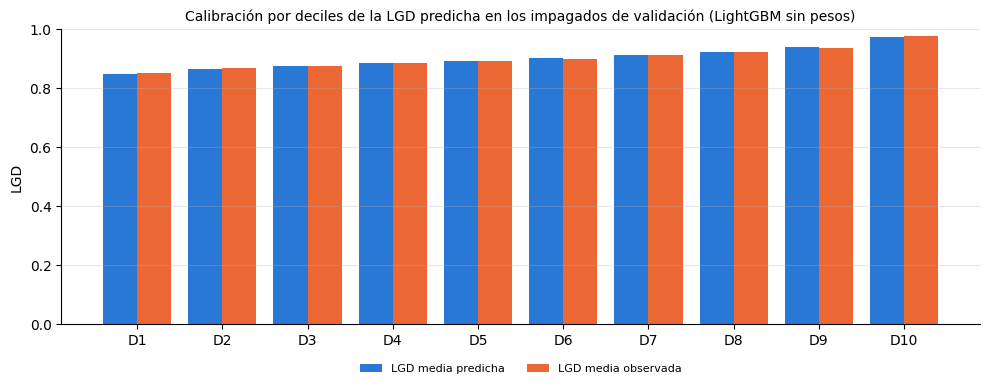

,LGD predicha,LGD observada
D1,0.847,0.851
D2,0.866,0.868
D3,0.876,0.874
D4,0.885,0.885
D5,0.894,0.891
D6,0.902,0.898
D7,0.911,0.911
D8,0.922,0.922
D9,0.938,0.938
D10,0.974,0.975


,% gain
meses_en_cartera,48.1
pct_plazo_transcurrido,10.5
addr_state,4.3
interest_rate,3.2
annual_income,3.0
emp_title_clean,2.1
total_credit_revolving_bal,1.8
credit_hist_years,1.8
dept_paym_income_ratio,1.5
tot_num_credit_lines,1.4


In [22]:
# 1) Tabla resumen
tabla_lgd = pd.DataFrame(resultados_lgd).T.astype(float)
base, seg = tabla_lgd.loc["Media global", "MAE_euros"], tabla_lgd.loc["Medias plazo × madurez", "MAE_euros"]
tabla_lgd["mejora MAE_euros vs media (%)"] = 100 * (1 - tabla_lgd["MAE_euros"] / base)
tabla_lgd["mejora MAE_euros vs segmentos (%)"] = 100 * (1 - tabla_lgd["MAE_euros"] / seg)
display(tabla_lgd.round(4))
mejor_lgbm_lgd = min(modelos_lgd, key=lambda n: resultados_lgd[n]["MAE_euros"])
print(f"Mejor LightGBM por MAE_euros: {mejor_lgbm_lgd}\n")

# 2) Calibración por grupos: Σ pérdida estimada / Σ pérdida real (con la EAD real)
comparar_lgd = ["Medias plazo × madurez", "LightGBM sin pesos", "LightGBM ponderado por EAD"]


def calibracion_lgd(grupo):
    t = pd.DataFrame({"n": apto_val.groupby(grupo, observed=True).size(),
                      "LGD real media": apto_val.groupby(grupo, observed=True)["lgd"].mean()})
    perdida_real = apto_val["perdida_real"].groupby(grupo, observed=True).sum()
    for nombre in comparar_lgd:
        perdida_pred = pd.Series(lgd_pred_val[nombre] * apto_val["ead"].to_numpy(), index=apto_val.index)
        t[nombre] = perdida_pred.groupby(grupo, observed=True).sum() / perdida_real
    return t


for titulo, grupo in (("plazo", apto_val["loan_term_months"].rename("plazo")),
                      ("tramo de madurez", tramo_madurez(apto_val).rename("% plazo transcurrido")),
                      ("año de concesión", apto_val["issue_date_year"].rename("año")),
                      ("decil de EAD", pd.qcut(apto_val["ead"], 10).rename("EAD (€)"))):
    print(f"Σ pérdida estimada / Σ pérdida real por {titulo}:")
    display(calibracion_lgd(grupo).round(3))

# 3) Calibración por deciles de la LGD predicha (mejor LightGBM)
pred_mejor = pd.Series(lgd_pred_val[mejor_lgbm_lgd], index=apto_val.index)
decil = pd.qcut(pred_mejor, 10, labels=[f"D{i}" for i in range(1, 11)])
calib_lgd = pd.DataFrame({"LGD predicha": pred_mejor.groupby(decil, observed=True).mean(),
                          "LGD observada": apto_val["lgd"].groupby(decil, observed=True).mean()})
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(calib_lgd))
ax.bar(x - 0.2, calib_lgd["LGD predicha"], width=0.4, color=COLOR_NO_IMPAGO, label="LGD media predicha")
ax.bar(x + 0.2, calib_lgd["LGD observada"], width=0.4, color=COLOR_IMPAGO, label="LGD media observada")
ax.set_xticks(x, calib_lgd.index)
ax.set_ylim(0, 1)
ax.set_ylabel("LGD")
ax.set_title(f"Calibración por deciles de la LGD predicha en los impagados de validación ({mejor_lgbm_lgd})", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False)
plt.tight_layout()
plt.show()
display(calib_lgd.round(3))

# 4) Importancia (gain) sumada por variable original
gain = pd.Series(modelos_lgd[mejor_lgbm_lgd].named_steps["modelo"].booster_.feature_importance("gain"),
                 index=X_lgd_train.columns)
origen = [c if c in candidatas else max((v for v in candidatas if c.startswith(v + "_")), key=len)
          for c in X_lgd_train.columns]
(gain.groupby(origen).sum() / gain.sum() * 100).sort_values(ascending=False).head(12).round(1).to_frame("% gain")

### 5.6 Modelo de LGD final

**Resultados de 5.4 y 5.5** (impagados aptos de validación):

| Modelo | MAE_lgd | MAE_euros | Σ pérdida est. / real | Mejora vs media | Mejora vs segmentos |
|---|---|---|---|---|---|
| Media global | 0,0886 | 933 € | 1,000 | — | −7,6% |
| Medias plazo × madurez | 0,0839 | 867 € | 1,005 | 7,1% | — |
| **LightGBM sin pesos** | **0,0821** | **846 €** | **1,004** | **9,3%** | **2,4%** |
| LightGBM ponderado por EAD | 0,0825 | 848 € | 1,000 | 9,1% | 2,2% |

**Qué nos dice:**
- **Hay mucho menos que ganar que en la EAD**, como anticipaba el EDA. La media global ya tiene un error de solo 933 € por impagado, porque casi todas las LGD están entre 0,85 y 1. El mejor modelo lo baja un 9% (frente al 20% de la EAD).
- **La señal es la madurez**:
  - los segmentos plazo × madurez reproducen el patrón del EDA, con LGD ≈ 1 en los préstamos más recientes y ~0,87 en los vencidos;
  - en LightGBM, `meses_en_cartera` (48%) y `pct_plazo_transcurrido` (11%) suman casi el 60% de la importancia;
  - el resto se reparte en muchas variables con un 1–4% cada una (estado, tipo de interés, ingresos, profesión...): pequeñas diferencias regionales o de perfil en la tasa de recobro.
- **LightGBM mejora a los segmentos en un 2,4%**, por encima del umbral del 2% fijado antes de ver los resultados. La mejora es pequeña (unos 21 € por impagado), pero tiene una ventaja clara en calibración:
  - **por año de concesión**, los segmentos infraestiman la pérdida de las añadas 2009–2012 (0,93–0,98), mientras que LightGBM queda entre 0,97 y 1,02 en todas las añadas con volumen. Al usar `meses_en_cartera` en continuo, recoge la madurez con más precisión que 6 tramos;
  - la **inmadurez del recobro de 2017 y 2018** queda bien recogida por todos los modelos (1,00–1,01);
  - **por deciles de la LGD predicha**, la calibración es casi perfecta: de 0,847 a 0,974 predicho frente a 0,851–0,975 observado.
- **Ponderar por EAD vuelve a no cambiar casi nada**: el MAE_euros es prácticamente igual y la calibración por grupos es algo más plana (Σ = 1,000 frente a 1,004). Por coherencia con la EAD y por tener la menor MAE_euros, nos quedamos con el **sin pesos**. El 0,4% de sobreestimación global que tiene va en la dirección conservadora.

**Elegido: LightGBM sin pesos.** No hace falta ajustar hiperparámetros: con 273 árboles y esta calibración no hay margen apreciable.

**Qué hace la celda**: guarda `modelo_lgd`, un `Pipeline` que recibe las columnas originales y devuelve la LGD. Lo aplica a **todos** los préstamos de validación, impagados o no: para un préstamo que no ha impagado, la LGD predicha es "qué parte de la EAD se perdería si impagara". Guarda `lgd_val` para la sección del ECL.

**Cómo leer la salida**: LGD predicha media en impagados y no impagados de validación. En los no impagados debería salir algo más alta, porque hay más préstamos recientes, en los que un impago todavía no habría tenido tiempo de recobrarse.

**Resultado**: 0,924 en los no impagados frente a 0,902 en los impagados, con un rango de predicciones de 0,72 a 1,00. Es lo esperado. Esta LGD entrará en el ECL multiplicada por la PD y la EAD.

In [23]:
elegido_lgd = "LightGBM sin pesos"
assert elegido_lgd == mejor_lgbm_lgd, "El mejor LightGBM por MAE_euros no es el elegido: revisar 5.5"
assert tabla_lgd.loc[elegido_lgd, "mejora MAE_euros vs segmentos (%)"] > 2, "No supera el criterio del 2% frente a los segmentos"
modelo_lgd = modelos_lgd[elegido_lgd]     # Pipeline: columnas originales -> LGD

# LGD de TODOS los préstamos de validación: el ECL se calcula sobre toda la cartera
lgd_val = pd.Series(modelo_lgd.predict(val[candidatas]), index=val.index, name="lgd_pred")

# Comprobaciones
assert lgd_val.between(0, 1).all(), "LGD predicha fuera de [0, 1]"
assert np.allclose(lgd_val.loc[apto_val.index], lgd_pred_val[elegido_lgd]), "No coincide con la evaluación de 5.4"

pd.DataFrame({
    "n": val.groupby("impago").size(),
    "LGD predicha media": lgd_val.groupby(val["impago"]).mean(),
    "LGD predicha mín.": lgd_val.groupby(val["impago"]).min(),
    "LGD predicha máx.": lgd_val.groupby(val["impago"]).max(),
}).rename(index={0: "no impago", 1: "impago"}).round(3)

,n,LGD predicha media,LGD predicha mín.,LGD predicha máx.
impago,,,,
no impago,297588,0.924,0.721,0.999
impago,44755,0.902,0.779,0.999


## 6. ECL en validación y diagnóstico sin margen

Ya tenemos las tres piezas del ECL:

ECL_i = PD_i × LGD_i × EAD_i

- **PD**: viene de `02_modelo_pd.ipynb` (LightGBM, sección 7).
- **LGD**: `modelo_lgd`, sección 5.
- **EAD**: `modelo_ead`, sección 4, con EAD = CCF × importe.

En esta sección calculamos el ECL de cada préstamo de validación **sin ningún margen** y lo evaluamos con los criterios del Comité de Riesgos (planteados al inicio de `01_eda.ipynb`). Así vemos de dónde partimos y cuánto margen hace falta. El diseño del margen será el paso siguiente.

### 6.1 Cargar la PD de validación y test

**Qué hace**: lee `data/processed/pd_val_test.pkl`, el fichero que exporta la sección 8 de `02_modelo_pd.ipynb`, y separa la PD de validación y la de test.

**Por qué las comprobaciones son imprescindibles**: el ECL multiplica la PD, la LGD y la EAD **del mismo préstamo**. Si las PD vinieran desordenadas o de otro split, multiplicaríamos la PD de un préstamo por la EAD de otro, y el resultado no tendría sentido aunque el código no diera error. Por eso se comprueba que:
- los índices del fichero son **exactamente** los de nuestro `val` y nuestro `test`, lo que confirma que los dos notebooks hacen el mismo split;
- el `impago` guardado coincide préstamo a préstamo con el nuestro.

Después se reordenan las PD con el índice de `val` y de `test`, para que estén alineadas fila a fila.

**Cómo leer la salida**: la PD media de cada partición, que debe estar cerca de la tasa de impago (13,07%), como en la calibración de la sección 7 de `02_modelo_pd.ipynb`.

In [24]:
RUTA_PD = "data/processed/pd_val_test.pkl"     # generado por la sección 8 de 02_modelo_pd.ipynb
pd_guardada = pd.read_pickle(RUTA_PD)

pd_por_particion = {}
for nombre, parte in (("val", val), ("test", test)):
    trozo = pd_guardada[pd_guardada["particion"] == nombre]
    assert set(trozo.index) == set(parte.index) and len(trozo) == len(parte), f"Los índices de {nombre} no coinciden"
    trozo = trozo.reindex(parte.index)                                   # mismo orden que nuestro DataFrame
    assert (trozo["impago"] == parte["impago"]).all(), f"El impago de {nombre} no coincide préstamo a préstamo"
    assert trozo["pd"].between(0, 1).all()
    pd_por_particion[nombre] = trozo["pd"]

pd_val, pd_test = pd_por_particion["val"], pd_por_particion["test"]
pd.DataFrame({"n": [len(pd_val), len(pd_test)],
              "PD media": [pd_val.mean(), pd_test.mean()]}, index=["validación", "test"]).round(4)

,n,PD media
validación,342343,0.1307
test,427929,0.1306


### 6.2 Función de evaluación

**Qué hace**: implementa los criterios de aceptación y las métricas del Comité de Riesgos. Todas se calculan **préstamo a préstamo** (j = cada préstamo).

| Métrica / criterio | Cálculo | Objetivo |
|---|---|---|
| **ECL total** | Σ ECL_i | Lo más bajo posible... |
| **ECL total / pérdida real total** | Σ ECL_i / Σ pérdida_i | ...pero **> 1** (criterio 1: si no, el modelo no es aceptable) |
| **% de préstamos con ECL_i < pérdida_i** | proporción de filas | **≤ 10%** (criterio 2: si no, el modelo no es aceptable) |
| **MAE** | media de \|ECL_i − pérdida_i\| sobre **todos** los préstamos | Lo más bajo posible |
| **MAPE** | media de \|ECL_i − pérdida_i\| / pérdida_i, **solo con pérdida_i > 1** | Lo más bajo posible |

**Por qué el MAPE solo con pérdida > 1**: la pérdida real de los no impagados es 0, y no se puede dividir entre 0. Por eso se calcula solo con los préstamos con pérdida > 1 €, así que el MAPE **solo mira impagados**.

**Cómo se reparten las métricas entre impagados y no impagados** (clave para el margen):
- **No impagados** (87%): pérdida real 0. Su ECL siempre es > 0, así que **cumplen el criterio del 10% solos**, pero cada euro de ECL que les ponemos **suma al MAE**.
- **Impagados** (13%): su pérdida real es EAD × LGD. Su ECL es PD × LGD × EAD con PD < 1, así que **casi siempre queda por debajo**. Subirles el ECL mejora el MAPE y ayuda a cumplir el criterio del 10%.

Los dos criterios de aceptación se devuelven como columnas sí/no, para verlas de un vistazo en las tablas.

In [25]:
def evaluar_ecl(ecl, perdida):
    """Criterios de aceptación y métricas del ECL, préstamo a préstamo (j = cada préstamo)."""
    ecl, perdida = np.asarray(ecl, dtype=float), np.asarray(perdida, dtype=float)
    error = np.abs(ecl - perdida)
    con_perdida = perdida > 1                                   # el MAPE solo se puede calcular con pérdida > 0
    pct_debajo = 100 * (ecl < perdida).mean()
    return {"ECL total (M€)": ecl.sum() / 1e6,
            "pérdida real total (M€)": perdida.sum() / 1e6,
            "ECL / pérdida real": ecl.sum() / perdida.sum(),
            "% préstamos con ECL < pérdida": pct_debajo,
            "MAE (€)": error.mean(),
            "MAPE (%)": 100 * (error[con_perdida] / perdida[con_perdida]).mean(),
            "cumple ECL > pérdida": ecl.sum() > perdida.sum(),
            "cumple ≤ 10%": pct_debajo <= 10}


resultados_ecl = {}
print(f"Préstamos de validación: {len(val):,} | impagados: {val['impago'].mean():.2%} | "
      f"con pérdida real > 1 €: {(val['perdida_real'] > 1).mean():.2%}")

Préstamos de validación: 342,343 | impagados: 13.07% | con pérdida real > 1 €: 13.02%


### 6.3 ECL sin margen: de dónde partimos

**Qué hace**: calcula ECL_i = PD_i × LGD_i × EAD_i para los 342.343 préstamos de validación y lo evalúa con `evaluar_ecl`. Luego hace dos diagnósticos para preparar el margen.

**1) Desglose por impago**: ECL total, pérdida total y % por debajo, separando impagados y no impagados. Muestra dónde está el problema.

**2) Cuánto habría que multiplicar el ECL de cada impagado para cubrirlo**: para cada impagado, el cociente pérdida_i / ECL_i es el **factor que haría falta** para que su ECL igualara su pérdida. Por ejemplo, si un impagado tiene PD = 0,25 y la LGD y la EAD están bien estimadas, el factor es ~4.
- Si ordenamos esos factores, sabemos **qué factor global k haría falta** para cubrir la proporción de impagados que exige el criterio del 10%.
- El criterio permite como mucho un 10% de préstamos por debajo. Como los impagados son ~13%, hay que **cubrir al menos (13,07% − 10%) / 13,07% ≈ 24% de los impagados**. Con algo de holgura (objetivo 9%), un ~31%.
- La tabla muestra, para varios objetivos, el factor k necesario y **cuánto costaría** en ECL total si se aplicara a todos los préstamos por igual (el margen más simple).

**Cómo leerlo**:
- Sin margen, esperamos un ECL total cercano a la pérdida real, porque los tres modelos están calibrados, y ~13% de préstamos por debajo, así que **se incumple el criterio del 10%**.
- El coste de la tabla 2 es el **peor caso**: el margen uniforme. Es la referencia que el diseño del margen tendrá que mejorar.

In [26]:
# ECL sin margen de cada préstamo de validación
ecl_val = (pd_val * lgd_val * ead_val).rename("ecl")
perdida_val = val["perdida_real"]
assert ecl_val.notna().all() and (ecl_val >= 0).all()

resultados_ecl["Sin margen"] = evaluar_ecl(ecl_val, perdida_val)
display(pd.DataFrame(resultados_ecl).T)

# 1) Desglose por impago
debajo = ecl_val < perdida_val
print("Desglose por impago:")
display(pd.DataFrame({
    "n": val.groupby("impago").size(),
    "% de la cartera": val.groupby("impago").size() / len(val) * 100,
    "ECL total (M€)": ecl_val.groupby(val["impago"]).sum() / 1e6,
    "pérdida real total (M€)": perdida_val.groupby(val["impago"]).sum() / 1e6,
    "% del grupo con ECL < pérdida": debajo.groupby(val["impago"]).mean() * 100,
    "% de la cartera con ECL < pérdida": debajo.groupby(val["impago"]).sum() / len(val) * 100,
}).rename(index={0: "no impago", 1: "impago"}).round(2))

# 2) Factor necesario para cubrir a cada impagado y coste de un margen uniforme
imp = val["impago"] == 1
factor = (perdida_val[imp] / ecl_val[imp]).sort_values()
filas = {}
for objetivo in (10, 9, 8):
    max_debajo = int(objetivo / 100 * len(val))                         # préstamos que pueden quedar por debajo
    a_cubrir = max(imp.sum() - max_debajo, 0)      # impagados que hay que dejar con ECL >= pérdida
    k = factor.iloc[a_cubrir - 1] if a_cubrir > 0 else 1.0   # los de pérdida 0 tienen factor 0: ya cubiertos
    filas[f"≤ {objetivo}% por debajo"] = {
        "impagados a cubrir": a_cubrir, "% de los impagados": 100 * a_cubrir / imp.sum(),
        "factor k uniforme": k, "ECL total con k (M€)": k * ecl_val.sum() / 1e6,
        "ECL / pérdida real con k": k * ecl_val.sum() / perdida_val.sum()}
print("Factor necesario por impagado (pérdida / ECL), percentiles:")
display(factor.quantile([0.1, 0.25, 0.5, 0.75, 0.9]).rename("factor").round(2).to_frame().T)
print("Margen uniforme ECL × k necesario para cumplir el criterio del 10% (el caso más caro):")
pd.DataFrame(filas).T.round(2)

,ECL total (M€),pérdida real total (M€),ECL / pérdida real,% préstamos con ECL < pérdida,MAE (€),MAPE (%),cumple ECL > pérdida,cumple ≤ 10%
Sin margen,445.72151,444.9512,1.001731,12.786883,1979.127259,83.560784,True,False


Desglose por impago:


,n,% de la cartera,ECL total (M€),pérdida real total (M€),% del grupo con ECL < pérdida,% de la cartera con ECL < pérdida
impago,,,,,,
no impago,297588,86.93,338.11,0.00,0.00,0.00
impago,44755,13.07,107.62,444.95,97.81,12.79


Factor necesario por impagado (pérdida / ECL), percentiles:


,0.10,0.25,0.50,0.75,0.90
factor,2.0,2.93,4.66,7.93,13.67


Margen uniforme ECL × k necesario para cumplir el criterio del 10% (el caso más caro):


,impagados a cubrir,% de los impagados,factor k uniforme,ECL total con k (M€),ECL / pérdida real con k
≤ 10% por debajo,10521.0,23.51,2.84,1266.83,2.85
≤ 9% por debajo,13945.0,31.16,3.31,1474.74,3.31
≤ 8% por debajo,17368.0,38.81,3.79,1689.33,3.80


### 6.4 Margen conservador: el problema y las estrategias

**El punto de partida (6.3).** Sin margen:
- el ECL total supera la pérdida real por solo un 0,2%: el criterio 1 se cumple, pero sin holgura;
- el **12,8%** de los préstamos tiene un ECL por debajo de su pérdida: el criterio 2 (≤ 10%) **se incumple**.

Casi todos los que quedan por debajo son impagados: su ECL es PD × LGD × EAD, mientras que su pérdida es LGD × EAD, porque ya han impagado. Como la PD es menor que 1, su ECL siempre se queda corto. Hay que **"cubrir"** (ECL ≥ pérdida) a ~1 de cada 4 impagados.

**El problema es que no sabemos quién va a impagar.** En test no se conoce el impago. Todo margen tiene que decidirse con lo que sabemos de cada préstamo (PD, LGD, EAD) y se aplica también a los no impagados. Cada euro que añadimos a un no impagado sube el ECL total y el MAE sin cubrir a nadie. Lo que buscamos es el margen que cubre suficientes impagados **gastando lo mínimo**.

**Estrategias que comparamos:**

| Estrategia | Cómo funciona | Parámetros |
|---|---|---|
| **Uniforme** | ECL_i = k × PD_i × LGD_i × EAD_i para todos | k |
| **Selectiva por PD** | Los préstamos con **mayor PD** reciben ECL_i = m × LGD_i × EAD_i (su pérdida si impagan, con un colchón m); el resto, su ECL normal | q (fracción cubierta) y m |
| **Selectiva por PD / (LGD × EAD)** | Igual, pero eligiendo los préstamos con mayor **PD / (LGD × EAD)** | q y m |

**La idea de la cobertura selectiva.** En lugar de subir un poco el ECL de todos, se sube **del todo** el de unos pocos:
- A un préstamo "cubierto" se le pone como ECL su **pérdida estimada si impagara**, LGD × EAD, multiplicada por un colchón **m** (1,0 a 1,6). El colchón hace falta porque la LGD y la EAD reales pueden ser mayores que las estimadas. Si el préstamo impaga, su ECL será mayor o igual que su pérdida y deja de contar en el criterio del 10%.
- **¿A quién cubrir?** Cubrir un préstamo cuesta m × LGD × EAD euros de ECL, y "rinde" (cubre un impagado) con probabilidad PD. Así que la **probabilidad de cubrir un impagado por cada euro de margen** es proporcional a **PD / (LGD × EAD)**. Ordenando por este cociente se cubren primero los préstamos que más probablemente impagan y que menos cuesta cubrir (pérdida pequeña). Es la misma lógica que llenar una mochila con los objetos de más valor por kilo.
- Ordenar solo por **PD** ignora el coste: puede cubrir un préstamo de 35.000 € con PD 0,5 cuando con ese dinero se cubrirían varios préstamos pequeños con PD 0,4.

**Cómo se aplica a préstamos nuevos.** El margen no se guarda como "el 20% de la cartera", sino como un **umbral** de la puntuación (PD, o PD / (LGD × EAD)): se cubren los préstamos con puntuación ≥ umbral. El umbral se calcula en validación y se aplica tal cual a test.

**Qué hace la celda**: define las funciones que usaremos en el resto de la sección:
- `aplicar_margen(pd, lgd, ead, margen)`: calcula el ECL con un margen dado (un diccionario con la estrategia y sus parámetros).
- `rejilla(pd, lgd, ead, perdida)`: prueba todas las combinaciones de parámetros y evalúa cada una con `evaluar_ecl`:
  - uniforme: k de 1 a 5 de 0,01 en 0,01;
  - selectivas: q del 5% al 40% de la cartera de 0,5 en 0,5 puntos, y m de 1,0 a 1,6.
- `elegir(tabla, objetivo)`: de todas las combinaciones que dejan como mucho un `objetivo`% de préstamos por debajo y un ECL total mayor que la pérdida real, devuelve la de **menor ECL total**, que es la métrica principal.

In [27]:
CRITERIOS = {"selectiva por PD": "PD", "selectiva por PD/(LGD×EAD)": "PD/(LGD×EAD)"}
K_REJILLA = np.round(np.arange(1.0, 5.0001, 0.01), 2)           # margen uniforme
Q_REJILLA = np.round(np.arange(0.05, 0.4001, 0.005), 3)         # fracción de la cartera cubierta
M_REJILLA = np.round(np.arange(1.0, 1.6001, 0.1), 1)            # colchón sobre LGD × EAD


def puntuacion(pd_, lgd_, ead_, criterio):
    """Orden de cobertura: la PD, o la PD por euro de pérdida si impaga."""
    return pd_ if criterio == "PD" else pd_ / np.maximum(lgd_ * ead_, 1.0)


def aplicar_margen(pd_, lgd_, ead_, margen):
    """ECL de cada préstamo con un margen: {'estrategia': 'uniforme', 'k'} o
    {'estrategia': 'selectiva', 'criterio', 'umbral', 'm'}."""
    pd_, lgd_, ead_ = (np.asarray(x, dtype=float) for x in (pd_, lgd_, ead_))
    base = pd_ * lgd_ * ead_
    if margen["estrategia"] == "uniforme":
        return margen["k"] * base
    cubierto = puntuacion(pd_, lgd_, ead_, margen["criterio"]) >= margen["umbral"]
    return np.where(cubierto, np.maximum(base, margen["m"] * lgd_ * ead_), base)


def rejilla(pd_, lgd_, ead_, perdida, estrategias=("uniforme", *CRITERIOS)):
    """Evalúa todas las combinaciones de parámetros de las estrategias indicadas."""
    pd_, lgd_, ead_ = (np.asarray(x, dtype=float) for x in (pd_, lgd_, ead_))
    filas = []
    if "uniforme" in estrategias:
        for k in K_REJILLA:
            margen = {"estrategia": "uniforme", "k": k}
            filas.append({"nombre": "uniforme", **margen, **evaluar_ecl(aplicar_margen(pd_, lgd_, ead_, margen), perdida)})
    for nombre, criterio in CRITERIOS.items():
        if nombre not in estrategias:
            continue
        orden = np.sort(puntuacion(pd_, lgd_, ead_, criterio))[::-1]      # de mayor a menor puntuación
        for q in Q_REJILLA:
            umbral = orden[int(q * len(orden)) - 1]                        # cubre la fracción q de mayor puntuación
            for m in M_REJILLA:
                margen = {"estrategia": "selectiva", "criterio": criterio, "umbral": umbral, "m": m}
                filas.append({"nombre": nombre, **margen, "q": q,
                              **evaluar_ecl(aplicar_margen(pd_, lgd_, ead_, margen), perdida)})
    return pd.DataFrame(filas)


def elegir(tabla, objetivo):
    """La combinación de menor ECL total con ≤ objetivo % por debajo y ECL total > pérdida real."""
    validas = tabla[(tabla["% préstamos con ECL < pérdida"] <= objetivo) & (tabla["ECL / pérdida real"] > 1)]
    return validas.loc[validas["ECL total (M€)"].idxmin()]


def margen_de(fila):
    """Diccionario de margen a partir de una fila de la rejilla."""
    if fila["estrategia"] == "uniforme":
        return {"estrategia": "uniforme", "k": float(fila["k"])}
    return {"estrategia": "selectiva", "criterio": fila["criterio"], "umbral": float(fila["umbral"]), "m": float(fila["m"])}


def describir(fila):
    if fila["estrategia"] == "uniforme":
        return f"k = {fila['k']:.2f}"
    return f"cubre el {100 * fila['q']:.1f}% de la cartera, m = {fila['m']:.1f}"


# Comprobación: sin margen (k = 1) se reproduce el ECL de 6.3
arrays_val = (pd_val.to_numpy(), lgd_val.to_numpy(), ead_val.to_numpy())
assert np.allclose(aplicar_margen(*arrays_val, {"estrategia": "uniforme", "k": 1.0}), ecl_val)
print(f"Combinaciones a evaluar: {len(K_REJILLA)} uniformes + "
      f"{len(CRITERIOS) * len(Q_REJILLA) * len(M_REJILLA)} selectivas")

Combinaciones a evaluar: 401 uniformes + 994 selectivas


### 6.5 Curva de coste: cuánto cuesta cada décima de holgura

**Qué hace**: evalúa toda la rejilla en validación y, para cada estrategia y cada **objetivo de holgura** (9%, 9,25%, 9,5%, 9,75% y 10% de préstamos por debajo), elige la combinación más barata que lo cumple.

**Por qué varios objetivos.** El criterio es ≤ 10%, pero el margen se ajusta en validación y se aplica a test. En test el % por debajo saldrá algo distinto, así que necesitamos **holgura**. ¿Cuánta? Cada décima de holgura cuesta ECL, y el ECL total es la métrica principal. Esta curva dice **cuánto cuesta** cada nivel de holgura. Las dos celdas siguientes (6.6 y 6.7) dicen **cuánta hace falta**.

**Cómo leer la tabla y el gráfico:**
- **ECL / pérdida real**: cuántas veces la pérdida real es el ECL total. Cuanto más bajo, mejor (siempre > 1).
- Cada línea del gráfico es una estrategia. Debería verse:
  - que la uniforme es la más cara con diferencia;
  - que la selectiva por PD / (LGD × EAD) es la más barata;
  - que **cuanto más cerca del 10% se apunta, menos ECL**.
- **MAE y MAPE**: el margen empeora el MAE (más ECL en no impagados) y puede mejorar el MAPE (los impagados cubiertos quedan cerca de su pérdida). Son métricas secundarias: la elección se hace por ECL total, cumpliendo los dos criterios de aceptación.

Rejilla evaluada en 22 s (1,395 combinaciones)



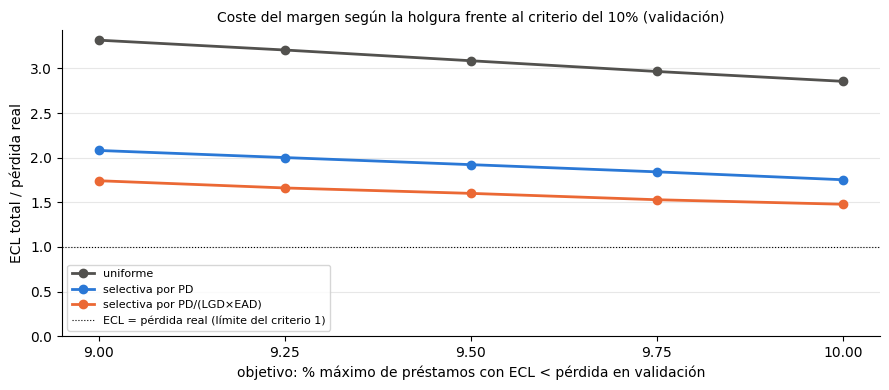

Estrategia más barata: selectiva por PD/(LGD×EAD)


,estrategia,objetivo (%),parámetros,% con ECL < pérdida,ECL / pérdida real,ECL total (M€),MAE (€),MAPE (%)
0,uniforme,9.00,k = 3.31,9.00,3.316,1475.3,3870.0,82.9
1,uniforme,9.25,k = 3.20,9.24,3.206,1426.3,3760.0,81.5
2,uniforme,9.50,k = 3.08,9.50,3.085,1372.8,3643.0,80.1
3,uniforme,9.75,k = 2.96,9.75,2.965,1319.3,3528.0,78.8
4,uniforme,10.00,k = 2.85,9.99,2.855,1270.3,3424.0,77.8
5,selectiva por PD,9.00,"cubre el 13.0% de la cartera, m = 1.3",8.98,2.080,925.7,2726.0,90.8
6,selectiva por PD,9.25,"cubre el 12.0% de la cartera, m = 1.3",9.20,2.001,890.3,2662.0,90.6
7,selectiva por PD,9.50,"cubre el 11.0% de la cartera, m = 1.3",9.43,1.922,855.0,2599.0,90.0
8,selectiva por PD,9.75,"cubre el 10.0% de la cartera, m = 1.3",9.67,1.841,819.2,2537.0,86.1
9,selectiva por PD,10.00,"cubre el 8.0% de la cartera, m = 1.4",9.98,1.753,779.8,2505.0,89.1


In [28]:
OBJETIVOS = [9.0, 9.25, 9.5, 9.75, 10.0]

t0 = time.time()
tabla_margen = rejilla(*arrays_val, perdida_val.to_numpy())
print(f"Rejilla evaluada en {time.time() - t0:.0f} s ({len(tabla_margen):,} combinaciones)\n")

filas = []
for nombre in ("uniforme", *CRITERIOS):
    for objetivo in OBJETIVOS:
        f = elegir(tabla_margen[tabla_margen["nombre"] == nombre], objetivo)
        filas.append({"estrategia": nombre, "objetivo (%)": objetivo, "parámetros": describir(f),
                      "% con ECL < pérdida": f["% préstamos con ECL < pérdida"],
                      "ECL / pérdida real": f["ECL / pérdida real"], "ECL total (M€)": f["ECL total (M€)"],
                      "MAE (€)": f["MAE (€)"], "MAPE (%)": f["MAPE (%)"]})
curva = pd.DataFrame(filas)

fig, ax = plt.subplots(figsize=(9, 4))
colores = {"uniforme": COLOR_REF, "selectiva por PD": COLOR_NO_IMPAGO, "selectiva por PD/(LGD×EAD)": COLOR_IMPAGO}
for nombre, sub in curva.groupby("estrategia", sort=False):
    ax.plot(sub["objetivo (%)"], sub["ECL / pérdida real"], marker="o", lw=2, color=colores[nombre], label=nombre)
ax.axhline(1, color="black", lw=0.8, ls=":", label="ECL = pérdida real (límite del criterio 1)")
ax.set_ylim(0, None)
ax.set_xticks(OBJETIVOS)
ax.set_xlabel("objetivo: % máximo de préstamos con ECL < pérdida en validación")
ax.set_ylabel("ECL total / pérdida real")
ax.set_title("Coste del margen según la holgura frente al criterio del 10% (validación)", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

estrategia_ganadora = curva.groupby("estrategia")["ECL / pérdida real"].mean().idxmin()
print(f"Estrategia más barata: {estrategia_ganadora}")
curva.round({"% con ECL < pérdida": 2, "ECL / pérdida real": 3, "ECL total (M€)": 1, "MAE (€)": 0, "MAPE (%)": 1})

### 6.6 Bootstrap: ¿cuánto puede cambiar el % por debajo solo por azar?

**La pregunta**: si en validación el margen deja un 9,5% de préstamos por debajo, ¿podría dar más del 10% en test **solo por azar**, porque test es otra muestra de préstamos?

**Qué es el bootstrap.** Validación es una muestra de préstamos de la misma población que test (el split es aleatorio y estratificado). Para simular "otra muestra como test":
- se sacan al azar **con reemplazamiento** tantos préstamos de validación como tiene test (427.929);
- se calcula el % por debajo y el ECL / pérdida en esa muestra;
- se repite **1.000 veces**.

La dispersión de esos 1.000 resultados es la variabilidad que cabe esperar en test por azar.

**Qué hace la celda**: para la estrategia ganadora de 6.5 y cada objetivo, fija el margen elegido en validación y calcula en las 1.000 muestras:
- **% por debajo**: media, percentil 99 y máximo;
- **P(% > 10%)**: en qué proporción de las muestras se incumpliría el criterio del 10%;
- **P(ECL < pérdida)**: en qué proporción se incumpliría el criterio 1.

Se usan las mismas 1.000 muestras para todos los objetivos, para que la comparación sea justa.

**Qué esperamos**: con más de 400.000 préstamos, el % por debajo de una muestra apenas se mueve. La desviación típica teórica es raíz(0,095 × 0,905 / 427.929) ≈ 0,045 puntos. Así que el azar casi no debería preocupar salvo en el objetivo del 10% exacto.

**Lo que el bootstrap NO mide**: el margen se ha **elegido** mirando validación (el mejor q y m entre cientos). Eso lo hace un poco "a medida" de validación, y en datos nuevos rendirá algo peor. Ese **sobreajuste** se mide en 6.7.

In [29]:
N_BOOT = 1000
rng = np.random.default_rng(42)
sub_ganadora = tabla_margen[tabla_margen["nombre"] == estrategia_ganadora]
margenes = {obj: margen_de(elegir(sub_ganadora, obj)) for obj in OBJETIVOS}
ecl_por_obj = {obj: aplicar_margen(*arrays_val, margenes[obj]) for obj in OBJETIVOS}
perdida_arr = perdida_val.to_numpy()
debajo_por_obj = {obj: ecl < perdida_arr for obj, ecl in ecl_por_obj.items()}

pct_boot = {obj: np.empty(N_BOOT) for obj in OBJETIVOS}
ratio_boot = {obj: np.empty(N_BOOT) for obj in OBJETIVOS}
for b in range(N_BOOT):
    idx = rng.integers(0, len(val), size=len(test))           # una muestra "del tamaño de test"
    perdida_b = perdida_arr[idx].sum()
    for obj in OBJETIVOS:
        pct_boot[obj][b] = 100 * debajo_por_obj[obj][idx].mean()
        ratio_boot[obj][b] = ecl_por_obj[obj][idx].sum() / perdida_b

bootstrap = pd.DataFrame({
    obj: {"% por debajo en validación": 100 * debajo_por_obj[obj].mean(),
          "% medio (bootstrap)": pct_boot[obj].mean(),
          "desv. típica": pct_boot[obj].std(),
          "percentil 99": np.percentile(pct_boot[obj], 99),
          "máximo": pct_boot[obj].max(),
          "P(% > 10%) (%)": 100 * (pct_boot[obj] > 10).mean(),
          "ECL / pérdida mínimo": ratio_boot[obj].min(),
          "P(ECL < pérdida) (%)": 100 * (ratio_boot[obj] < 1).mean()}
    for obj in OBJETIVOS}).T
bootstrap.index.name = "objetivo (%)"
print(f"Estrategia: {estrategia_ganadora} | {N_BOOT} muestras de {len(test):,} préstamos")
bootstrap.round(3)

Estrategia: selectiva por PD/(LGD×EAD) | 1000 muestras de 427,929 préstamos


,% por debajo en validación,% medio (bootstrap),desv. típica,percentil 99,máximo,P(% > 10%) (%),ECL / pérdida mínimo,P(ECL < pérdida) (%)
objetivo (%),,,,,,,,
9.00,8.969,8.969,0.044,9.070,9.111,0.0,1.709,0.0
9.25,9.246,9.245,0.045,9.352,9.386,0.0,1.630,0.0
9.50,9.484,9.483,0.045,9.586,9.620,0.0,1.571,0.0
9.75,9.720,9.720,0.045,9.822,9.864,0.0,1.503,0.0
10.00,9.930,9.929,0.046,10.034,10.068,6.0,1.454,0.0


### 6.7 Sobreajuste: elegir el margen en una mitad y medirlo en la otra

**La pregunta**: el margen se elige probando cientos de combinaciones (q, m) en validación y quedándonos con la más barata que cumple el objetivo. Esa combinación está "hecha a medida": aprovecha que ciertos préstamos concretos de validación quedan justo por encima de su pérdida. En préstamos nuevos (test) ese ajuste fino no se repite, y el % por debajo **sube un poco**. ¿Cuánto?

**Cómo se mide: validación cruzada en dos mitades.**
1. Se parte validación en dos mitades al azar, estratificadas por impago (~171.000 préstamos cada una).
2. Con la **mitad A** se hace todo el proceso: rejilla, elección del margen para cada objetivo y cálculo del umbral.
3. Ese margen, **sin tocar**, se aplica a la **mitad B**, que no ha intervenido en la elección, y se mide su % por debajo. Es exactamente lo que pasará al aplicar a test el margen elegido en validación.
4. Se repite intercambiando las mitades (elegir en B, medir en A) y con **5 particiones distintas**: 10 mediciones en total.

**Es una prueba más dura que la real**: cada mitad tiene la mitad de préstamos que validación, así que su ruido es mayor (~0,07 puntos frente a ~0,045) y el margen elegido con ella está más "a medida". Si el objetivo aguanta aquí, aguantará en test.

**Cómo leer la tabla**, para cada objetivo:
- **% en la mitad de elección**: el que se ve al elegir; siempre ≤ objetivo, por construcción.
- **% en la mitad nueva**: media y máximo de las 10 mediciones. Es el dato clave.
- **aumento medio**: cuántos puntos sube el % al pasar a datos nuevos. Mide el sobreajuste.
- **ECL / pérdida mínimo en la mitad nueva**: el criterio 1 en el peor caso.
- **veces > 10%**: en cuántas de las 10 mediciones se habría incumplido el criterio del 10%.

In [30]:
arrays_completos = (*arrays_val, perdida_arr)
filas = []
t0 = time.time()
for semilla in range(5):
    mitad_a, mitad_b = train_test_split(np.arange(len(val)), test_size=0.5,
                                        stratify=val["impago"], random_state=semilla)
    for elegir_en, medir_en in ((mitad_a, mitad_b), (mitad_b, mitad_a)):
        pd_e, lgd_e, ead_e, perd_e = (x[elegir_en] for x in arrays_completos)
        pd_m, lgd_m, ead_m, perd_m = (x[medir_en] for x in arrays_completos)
        tabla_e = rejilla(pd_e, lgd_e, ead_e, perd_e, estrategias=(estrategia_ganadora,))
        for obj in OBJETIVOS:
            f = elegir(tabla_e, obj)
            ecl_m = aplicar_margen(pd_m, lgd_m, ead_m, margen_de(f))   # margen elegido en la otra mitad, sin tocar
            filas.append({"objetivo (%)": obj, "semilla": semilla,
                          "% en la mitad de elección": f["% préstamos con ECL < pérdida"],
                          "% en la mitad nueva": 100 * (ecl_m < perd_m).mean(),
                          "ECL / pérdida en la mitad nueva": ecl_m.sum() / perd_m.sum()})
mitades = pd.DataFrame(filas)
print(f"10 mediciones por objetivo en {time.time() - t0:.0f} s\n")

sobreajuste = mitades.groupby("objetivo (%)").agg(**{
    "% en la mitad de elección": ("% en la mitad de elección", "mean"),
    "% en la mitad nueva (media)": ("% en la mitad nueva", "mean"),
    "% en la mitad nueva (máximo)": ("% en la mitad nueva", "max"),
    "ECL / pérdida mínimo en la mitad nueva": ("ECL / pérdida en la mitad nueva", "min"),
    "veces > 10% (de 10)": ("% en la mitad nueva", lambda s: int((s > 10).sum())),
})
sobreajuste.insert(2, "aumento medio (puntos)",
                   sobreajuste["% en la mitad nueva (media)"] - sobreajuste["% en la mitad de elección"])
sobreajuste.round(3)

10 mediciones por objetivo en 55 s



,% en la mitad de elección,% en la mitad nueva (media),aumento medio (puntos),% en la mitad nueva (máximo),ECL / pérdida mínimo en la mitad nueva,veces > 10% (de 10)
objetivo (%),,,,,,
9.00,8.969,8.975,0.006,9.094,1.707,0
9.25,9.232,9.237,0.005,9.359,1.644,0
9.50,9.473,9.477,0.004,9.602,1.567,0
9.75,9.714,9.720,0.006,9.790,1.517,0
10.00,9.962,9.970,0.008,10.069,1.451,4


### 6.8 Elección del objetivo y margen final

**Regla de decisión**, fijada antes de ver los resultados: se elige el objetivo **más cercano al 10%** (el más barato) que cumpla a la vez:
1. **Bootstrap (6.6)**: P(% > 10%) < 1%, es decir, el azar del muestreo casi nunca lo lleva por encima del 10%.
2. **Mitades (6.7)**: **ninguna** de las 10 mediciones en datos nuevos supera el 10%. Así se cubre el sobreajuste de elegir el margen en validación.
3. **Criterio 1** con holgura en las dos pruebas: el ECL / pérdida mínimo, tanto en el bootstrap como en las mitades, debe ser > 1.

**Qué hace la celda**:
- aplica la regla y muestra para cada objetivo si pasa cada prueba;
- con el objetivo elegido, fija el **margen final** usando **toda la validación**: es el que se aplicará a test;
- compara las métricas en validación sin margen y con el margen final.

**Por qué el margen final se recalcula con toda la validación** (y no con una mitad): con el doble de préstamos, el umbral y el colchón se estiman con menos ruido. Las pruebas de 6.6 y 6.7 ya han medido lo que cabe esperar al pasar a datos nuevos, y la regla de decisión lo tiene en cuenta.

**Cómo leer la salida**:
- la tabla de decisión: una fila por objetivo, con ✔ / ✘ en cada prueba;
- el margen final: estrategia, umbral, colchón m y la fracción de validación que cubre;
- la comparación sin margen / con margen: ECL total, los dos criterios de aceptación, MAE y MAPE.

In [31]:
decision = pd.DataFrame({
    "P(% > 10%) bootstrap (%)": bootstrap["P(% > 10%) (%)"],
    "máximo % en mitad nueva": sobreajuste["% en la mitad nueva (máximo)"],
    "ECL / pérdida mínimo": np.minimum(bootstrap["ECL / pérdida mínimo"],
                                       sobreajuste["ECL / pérdida mínimo en la mitad nueva"]),
})
decision["1. bootstrap"] = decision["P(% > 10%) bootstrap (%)"] < 1
decision["2. mitades"] = decision["máximo % en mitad nueva"] <= 10
decision["3. ECL > pérdida"] = decision["ECL / pérdida mínimo"] > 1
decision["pasa"] = decision[["1. bootstrap", "2. mitades", "3. ECL > pérdida"]].all(axis=1)
pruebas = ["1. bootstrap", "2. mitades", "3. ECL > pérdida", "pasa"]
display(decision.round(3).astype({c: object for c in pruebas})
        .assign(**{c: decision[c].map({True: "✔", False: "✘"}) for c in pruebas}))

assert decision["pasa"].any(), "Ningún objetivo pasa las pruebas"
objetivo_final = max(obj for obj in OBJETIVOS if decision.loc[obj, "pasa"])
fila_final = elegir(sub_ganadora, objetivo_final)
margen_final = margen_de(fila_final)                           # elegido con TODA la validación
ecl_val_margen = pd.Series(aplicar_margen(*arrays_val, margen_final), index=val.index, name="ecl")

print(f"Objetivo elegido: ≤ {objetivo_final}% en validación")
print(f"Margen final: {estrategia_ganadora}, {describir(fila_final)}")
print(f"  umbral de la puntuación = {margen_final['umbral']:.3g}, colchón m = {margen_final['m']}")
cubiertos = ecl_val_margen > ecl_val
print(f"  préstamos de validación cubiertos: {cubiertos.mean():.1%} "
      f"(impagados entre los cubiertos: {val.loc[cubiertos, 'impago'].mean():.1%})\n")

resultados_ecl[f"Con margen (objetivo {objetivo_final}%)"] = evaluar_ecl(ecl_val_margen, perdida_val)
pd.DataFrame(resultados_ecl).T

,P(% > 10%) bootstrap (%),máximo % en mitad nueva,ECL / pérdida mínimo,1. bootstrap,2. mitades,3. ECL > pérdida,pasa
objetivo (%),,,,,,,
9.00,0.0,9.094,1.707,✔,✔,✔,✔
9.25,0.0,9.359,1.630,✔,✔,✔,✔
9.50,0.0,9.602,1.567,✔,✔,✔,✔
9.75,0.0,9.790,1.503,✔,✔,✔,✔
10.00,6.0,10.069,1.451,✘,✘,✔,✘


Objetivo elegido: ≤ 9.75% en validación
Margen final: selectiva por PD/(LGD×EAD), cubre el 15.5% de la cartera, m = 1.5
  umbral de la puntuación = 4.07e-05, colchón m = 1.5
  préstamos de validación cubiertos: 15.5% (impagados entre los cubiertos: 22.5%)



,ECL total (M€),pérdida real total (M€),ECL / pérdida real,% préstamos con ECL < pérdida,MAE (€),MAPE (%),cumple ECL > pérdida,cumple ≤ 10%
Sin margen,445.72151,444.9512,1.001731,12.786883,1979.127259,83.560784,True,False
Con margen (objetivo 9.75%),680.190757,444.9512,1.528686,9.720368,2456.13053,106.292285,True,True


### 6.9 Conclusiones del margen conservador

**1) La cobertura selectiva por PD / (LGD × EAD) es, con diferencia, la estrategia más barata (6.5).** Para el mismo objetivo de 9,75%:

| Estrategia | Parámetros | ECL / pérdida real |
|---|---|---|
| Uniforme | k = 2,96 | 2,97 |
| Selectiva por PD | cubre el 10% de la cartera, m = 1,3 | 1,84 |
| **Selectiva por PD / (LGD × EAD)** | **cubre el 15,5% de la cartera, m = 1,5** | **1,53** |

Ordenar por "probabilidad de impago por euro de pérdida" permite cubrir más préstamos (15,5% frente a 10%) gastando menos, porque prioriza los préstamos de pérdida pequeña. Frente al margen uniforme, el ECL total baja casi a la mitad.

**2) La holgura apenas hace falta: el % por debajo es muy estable.**
- **Azar (6.6)**: en 1.000 muestras del tamaño de test, la desviación típica del % por debajo es de **0,045 puntos**, justo la que predecía la fórmula. Con un objetivo de 9,75%, el máximo de las 1.000 muestras fue 9,86%. Ninguna superó el 10%.
- **Sobreajuste (6.7)**: al aplicar el margen elegido en una mitad a la otra mitad, el % por debajo solo sube **~0,005 puntos** de media. El margen tiene pocos parámetros (un umbral y un colchón), así que no se puede "hacer a medida" de validación.
- **Solo falla el objetivo del 10% exacto**: un 6% de las muestras del bootstrap y 4 de las 10 mediciones en mitades lo superan. Sin holgura, el criterio se incumpliría con frecuencia.

**3) Decisión: objetivo de 9,75%.** Es el más barato que pasa las tres pruebas. Pasar de 9% a 9,75% ahorra unos 95 M€ de ECL en validación (de 775 a 680 M€), y las pruebas dicen que ese ahorro no compromete el criterio.

**4) Resultado en validación con el margen final:**

| | ECL total | ECL / pérdida | % con ECL < pérdida | MAE | MAPE |
|---|---|---|---|---|---|
| Sin margen | 445,7 M€ | 1,002 | 12,8% ✘ | 1.979 € | 83,6% |
| **Con margen** | **680,2 M€** | **1,53** ✔ | **9,72%** ✔ | 2.456 € | 106,3% |

- Se cubre el 15,5% de la cartera de validación, y un 22,5% de los préstamos cubiertos son impagados (frente al 13% de la cartera): el criterio sí concentra la cobertura donde hay impagos.
- **El precio del margen es el MAE y el MAPE**. Los no impagados cubiertos reciben un ECL igual a 1,5 veces su pérdida si impagaran, aunque su pérdida real es 0. Y un impagado cubierto con m = 1,5 tiene un ECL ~50% por encima de su pérdida, lo que sube el MAPE. Es el coste inevitable del criterio del 10% préstamo a préstamo.
- **El criterio 1 queda con mucha holgura** (1,53; mínimo 1,50 en las pruebas). No es un objetivo en sí, sino una consecuencia del criterio del 10%, que es el que manda.

**5) Limitaciones y posibles mejoras:**
- En algunos objetivos el colchón elegido toca el borde de la rejilla (m = 1,6 con 9,5%). Ampliar la rejilla de m, o permitir un colchón que dependa del préstamo (por ejemplo, mayor cuanto más incierta sea la LGD × EAD estimada), podría abaratar algo el margen.
- La elección es por **ECL total**, la métrica principal. Si el Comité diera más peso a la precisión (MAE o MAPE), la combinación óptima de cobertura y colchón cambiaría.

**Margen final que se aplicará a test**: `margen_final`, estrategia selectiva por PD / (LGD × EAD), umbral 4,07e-05 y colchón m = 1,5, todo calculado con validación. Los préstamos de test con puntuación ≥ umbral recibirán ECL = máx(PD × LGD × EAD, 1,5 × LGD × EAD), y el resto, PD × LGD × EAD.

**Siguiente paso (sección 7)**: aplicar `modelo_ead`, `modelo_lgd`, la PD de test y `margen_final` a test, calcular las métricas y terminar con la celda final.

## 7. Aplicación a test y resultado final

Hasta aquí, **test no se ha usado para nada**: ni para entrenar, ni para elegir modelos, ni para ajustar el margen. Todo está **congelado**:

| Pieza | Objeto | Ajustado con |
|---|---|---|
| PD | `pd_test` (de `02_modelo_pd.ipynb`, sección 8) | train (+ early stopping en validación) |
| EAD | `modelo_ead` (LightGBM sin pesos, target CCF) | impagados de train |
| LGD | `modelo_lgd` (LightGBM sin pesos) | impagados aptos de train |
| Margen | `margen_final` (selectiva por PD / (LGD × EAD), umbral y m = 1,5) | validación |

Ahora se aplica todo a los 427.929 préstamos de test, **exactamente igual** que a un préstamo nuevo. La pérdida real de test, calculada en la sección 2 con las mismas fórmulas que en train, se usa **solo para evaluar**.

### 7.1 ECL de cada préstamo de test

**Qué hace**, para cada préstamo de test:
1. **EAD** = CCF predicho por `modelo_ead` × importe financiado.
2. **LGD** predicha por `modelo_lgd`.
3. **PD** cargada en 6.1.
4. **ECL con margen**:
   - si su puntuación PD / (LGD × EAD) es ≥ el umbral de validación, ECL = máx(PD × LGD × EAD, 1,5 × LGD × EAD);
   - si no, ECL = PD × LGD × EAD.

**Por qué el umbral y no "el 15,5% de test"**: el margen se congeló como un **umbral de la puntuación**, no como un porcentaje. Así cada préstamo de test se trata por sí mismo, sin mirar al resto de test, igual que se haría con un préstamo que llega solo. La proporción cubierta en test saldrá **cerca** del 15,5%, pero no exactamente.

**Cómo leer la salida**:
- los asserts garantizan que no hay nulos y que CCF, LGD y PD están entre 0 y 1;
- la tabla compara las medias de cada pieza en validación y en test. Deben ser casi iguales, porque las dos son muestras aleatorias de la misma población;
- el % de cartera cubierta por el margen también debe ser parecido en las dos.

In [32]:
# Las tres piezas, con los modelos congelados
ccf_test = pd.Series(modelo_ead.predict(test[candidatas]), index=test.index, name="ccf_pred")
ead_test = (ccf_test * test["funded_amnt"]).rename("ead_pred")
lgd_test = pd.Series(modelo_lgd.predict(test[candidatas]), index=test.index, name="lgd_pred")

# ECL sin margen y con el margen congelado en validación
arrays_test = (pd_test.to_numpy(), lgd_test.to_numpy(), ead_test.to_numpy())
ecl_test_sin_margen = pd.Series(aplicar_margen(*arrays_test, {"estrategia": "uniforme", "k": 1.0}), index=test.index)
ecl_test = pd.Series(aplicar_margen(*arrays_test, margen_final), index=test.index, name="ecl")
perdida_test = test["perdida_real"]

# Comprobaciones
for nombre, serie in (("PD", pd_test), ("CCF", ccf_test), ("LGD", lgd_test)):
    assert serie.notna().all() and serie.between(0, 1).all(), f"{nombre} de test fuera de [0, 1] o con nulos"
assert ecl_test.notna().all() and (ecl_test >= ecl_test_sin_margen).all(), "El margen no puede bajar el ECL"
assert ecl_test.index.equals(perdida_test.index)

cubiertos_val, cubiertos_test = ecl_val_margen > ecl_val, ecl_test > ecl_test_sin_margen
pd.DataFrame({
    "PD media": [pd_val.mean(), pd_test.mean()],
    "CCF medio": [ccf_val.mean(), ccf_test.mean()],
    "LGD media": [lgd_val.mean(), lgd_test.mean()],
    "EAD media (€)": [ead_val.mean(), ead_test.mean()],
    "ECL medio sin margen (€)": [ecl_val.mean(), ecl_test_sin_margen.mean()],
    "% cartera cubierta por el margen": [100 * cubiertos_val.mean(), 100 * cubiertos_test.mean()],
}, index=["validación", "test"]).round(3)

,PD media,CCF medio,LGD media,EAD media (€),ECL medio sin margen (€),% cartera cubierta por el margen
validación,0.131,0.707,0.921,10705.214,1301.973,15.500
test,0.131,0.707,0.921,10690.645,1302.735,15.488


### 7.2 Control: evaluación completa en test

**Qué hace**: evalúa el ECL de test con la misma función (`evaluar_ecl`, 6.2) que en validación, sin margen y con margen, y lo pone al lado de los resultados de validación. Añade dos comprobaciones de que test se parece a train y validación: la tasa de impago y la pérdida media por impagado.

**Por qué esta celda va aparte**: así la última celda queda como un resumen limpio con las dos cifras clave. El detalle (los criterios de aceptación, la pérdida real, las comparaciones) se muestra aquí.

**Cómo leer la tabla:**
- **Criterio 1** (ECL / pérdida real > 1): esperamos ~1,53, como en validación.
- **Criterio 2** (% con ECL < pérdida ≤ 10%): esperamos ~9,7–9,8%. Las pruebas de 6.6 y 6.7 decían que el % apenas se mueve entre muestras (desviación típica ~0,045 puntos) y que no hay sobreajuste apreciable.
- Si test se pareciera mucho menos a validación (tasa de impago o pérdida media muy distintas), sería una señal de alarma.
- **Esta es la primera y única vez que se mira el resultado en test.** Pase lo que pase, no se vuelve atrás a cambiar el margen: eso sería ajustar a test.

**Resultado en test:**

| | ECL total | ECL / pérdida | % con ECL < pérdida | MAE | MAPE |
|---|---|---|---|---|---|
| Validación con margen | 680,2 M€ | 1,529 | 9,72% | 2.456 € | 106,3% |
| **Test con margen** | **850,4 M€** | **1,531** ✔ | **9,73%** ✔ | **2.452 €** | **92,4%** |

- **Se cumplen los dos criterios de aceptación.** El ECL total es 1,53 veces la pérdida real (555,3 M€), y el 9,73% de los préstamos queda por debajo: 0,27 puntos de holgura frente al límite del 10%.
- **Test reproduce validación casi exactamente**: 9,73% frente a 9,72% por debajo, y 1,531 frente a 1,529 de ratio. Es lo que anticipaban el bootstrap (6.6) y la prueba de las mitades (6.7). El margen cubre el 15,49% de test frente al 15,50% de validación, y las medias de PD, CCF, LGD y EAD son prácticamente iguales.
- **Sin margen, el ECL total de test ya cuadra con la pérdida real** (1,004). Los tres modelos están bien calibrados. Todo el 53% extra es el precio del criterio del 10% préstamo a préstamo.
- **El MAPE es la única métrica que cambia algo** (92% frente a 106%). Es muy sensible a los impagados con pérdida real pequeña (justo por encima de 1 €), donde un ECL de unos cientos de euros da errores relativos enormes. Unos pocos de esos casos mueven la media, así que hay que leerlo con cautela.
- **Test se parece a train y validación**: la misma tasa de impago (13,07%) y casi la misma pérdida media por impagado (9.927 € frente a 9.939 € y 9.942 €).

In [33]:
resultados_test = {
    "Validación sin margen": resultados_ecl["Sin margen"],
    "Validación con margen": resultados_ecl[f"Con margen (objetivo {objetivo_final}%)"],
    "Test sin margen": evaluar_ecl(ecl_test_sin_margen, perdida_test),
    "Test con margen": evaluar_ecl(ecl_test, perdida_test),
}
display(pd.DataFrame(resultados_test).T)

pd.DataFrame({
    "n préstamos": [len(train), len(val), len(test)],
    "tasa de impago (%)": [100 * p["impago"].mean() for p in (train, val, test)],
    "pérdida media por impagado (€)": [p.loc[p["impago"] == 1, "perdida_real"].mean() for p in (train, val, test)],
    "pérdida real total (M€)": [p["perdida_real"].sum() / 1e6 for p in (train, val, test)],
}, index=["train", "validación", "test"]).round(2)

,ECL total (M€),pérdida real total (M€),ECL / pérdida real,% préstamos con ECL < pérdida,MAE (€),MAPE (%),cumple ECL > pérdida,cumple ≤ 10%
Validación sin margen,445.72151,444.9512,1.001731,12.786883,1979.127259,83.560784,True,False
Validación con margen,680.190757,444.9512,1.528686,9.720368,2456.13053,106.292285,True,True
Test sin margen,557.478138,555.33785,1.003854,12.785298,1976.867781,81.863595,True,False
Test con margen,850.360094,555.33785,1.531248,9.732456,2452.146757,92.363811,True,True


,n préstamos,tasa de impago (%),pérdida media por impagado (€),pérdida real total (M€)
train,1369371,13.07,9938.53,1779.18
validación,342343,13.07,9941.93,444.95
test,427929,13.07,9926.85,555.34


### 7.3 Resultado final

La última celda resume el resultado con **las dos cifras clave**, calculadas sobre test con los modelos y el margen congelados:

1. **ECL total estimado de la cartera de test** (cuanto más bajo, mejor, siempre que se cumplan los criterios de aceptación).
2. **Error préstamo a préstamo del ECL**: **MAE** (media de \|ECL_j − pérdida_j\| sobre todos los préstamos) y **MAPE** (lo mismo en proporción, solo con pérdida real > 1).

Los dos criterios de aceptación (ECL total > pérdida real y ≤ 10% de préstamos por debajo) se han comprobado en la celda anterior.

In [34]:
metricas_test = evaluar_ecl(ecl_test, perdida_test)
print(f"ECL total estimado (test): {ecl_test.sum():,.0f}")
print(f"MAE: {metricas_test['MAE (€)']:,.0f} | MAPE: {metricas_test['MAPE (%)']:.1f}%")

ECL total estimado (test): 850,360,094
MAE: 2,452 | MAPE: 92.4%
